# MySteth 2.0 — RQ4: Does confidence-based rejection actually improve calibration, or just discard hard cases?

**RQ4 (methods document).** *Selective rejection is assumed to improve reliability, but does rejecting low-confidence cases genuinely improve calibration on the retained set, or does it just remove difficult-but-correct predictions, inflating apparent reliability without real gain?*

Methodology, as written:
- MC-Dropout (30–50 passes) as baseline + 3-model deep ensemble + temperature scaling **on the RQ3 model**;
- accuracy–rejection curves and ECE before/after rejection at multiple thresholds;
- critically: **what fraction of rejected cases were actually correct** (the cost of rejection, not just the benefit);
- compare against Simone et al. (De Simone et al., 2025) and Zhang et al. (2024);
- metrics: ECE, AUROC (correct vs incorrect separation), rejection cost (correct predictions lost per threshold).

### The five MySteth 2.0 components and their role here

| # | Component | Role in this notebook |
|---|---|---|
| ① | SQA | Not used (recording quality vs uncertainty is RQ1). |
| ② | SSL | Inside the system model (Domain-SSL start, RQ2's rule). |
| ③ | Multi-task heads | Both heads of the RQ3 system model; **each task gets its own confidence gate** (RQ3's finding). |
| ④ | **UQ** | **The thing being tested:** seven UQ methods and the rejection they drive. |
| ⑤ | XAI | Off (RQ5). |

### Fixed, carried over from RQ3 (consistency across the RQ2–RQ6 redo)
- **Model:** the RQ3 system model, *Joint, Domain-SSL* (3 folds × 3 seeds), read from RQ3's saved units. **Nothing is trained.**
- Out-of-fold test predictions for all 942 patients; patient aggregation murmur = highest recording, outcome = mean.
- Validation thresholds (murmur: maximise weighted accuracy; outcome: minimise c_outcome), **kept fixed after rejection**.
- Temperatures fitted on each fold's calibration patients; ECE = positive-class probability, 10 bins.
- Metrics F1 (macro), Accuracy, Weighted accuracy, AUC (+ c_outcome); paired patient-group bootstrap with **the same 1,000 resamples as RQ3**.
- Patient level primary (the clinician gate defers a *patient*), recording level secondary.

### Decided for RQ4 (before writing this notebook)

| Decision | Choice |
|---|---|
| UQ methods (7) | `single` · `temp` · `mc` (40 passes) · `ens` (3 seeds) · **`ens_temp` (primary, fixed in advance)** · `mc_temp` (MC passes on temperature-scaled logits, like Zhang et al.) · `ens_mc_temp` (3 seeds × 40 passes, temperature-scaled: the methods document's full "MC + ensemble + temperature" wrapper) |
| Rejection score | **Chow's threshold-aware risk (primary):** risk = p / t below the decision threshold t, (1 − p) / (1 − t) above it (1 = on the threshold, 0 = certain). It equals max-probability when t = 0.5. **Alternative rankings:** binary entropy (the doc's literal measure, via RQ1), MC mutual information and ensemble spread (for `ens_temp`) |
| Tasks | murmur and outcome, each with its own gate |
| Curves | continuous (every patient a cutoff), drawn 0–90 % rejection, with random and oracle references |
| Reporting rates | **10 / 20 / 30 / 50 %** (20 % = De Simone's operating point) |
| "Genuine" calibration test | retained-set ECE vs **(i) before rejection** and **(ii) randomly rejecting the same number of patients** (paired CIs); oracle (errors rejected first) as the best-case bound |
| Rejection cost | share of rejected that were correct, share of correct predictions lost, share of errors removed, rejected FN / FP, each against what random rejection gives |
| Who's cut | class mix (Present / Abnormal deferral; sensitivity and specificity retained) and murmur grade I / II / III (descriptive) |
| Unknown murmur | excluded from murmur curves (no correctness); separate check of how many Unknown patients each cutoff would defer |
| Method comparison | AUROC (correct vs incorrect) and AURC, paired vs `ens_temp` |
| Pre-set answer rule | **Genuine calibration gain** = retained ECE lower than *both* before rejection *and* size-matched random rejection (CIs exclude 0). **Just discards hard cases** = no ECE gain beyond random, and/or correct predictions, Present patients or grade-I murmurs deferred at or above the random rate. |

### Kaggle setup
- **GPU on** (used only in section 3, ~10–20 min). Attach:
  - the CirCor v2 dataset;
  - the **RQ3 output** (`rq3_outputs`: units, models, folds, windows, thresholds, temperatures, predictions).
- Output: `/kaggle/working/rq4_outputs`.
- Why a GPU at all: RQ3 saved MC-Dropout passes for the seed-42 units only. `ens_mc_temp` needs them for seeds 123 and 7 too, so section 3 re-runs those six saved RQ3 models over all windows (no training) and checks that their deterministic logits match RQ3's exactly. Everything after section 3 is CPU.

In [1]:
import os, time, random, shutil, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import torchaudio.transforms as T
from scipy.optimize import minimize_scalar
from scipy.stats import rankdata, spearmanr
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Device:", device)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
NAVY, TEAL, ORANGE, RED, GRAY, PURPLE = "#1F3864", "#1F8A70", "#E67E22", "#C0392B", "#6B7280", "#7D3C98"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


@dataclass
class Config:
    # ---- EDIT THESE PATHS to match your Kaggle inputs ----
    circor_root: str = "/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2"
    rq3_dir: str = "/kaggle/input/notebooks/tusharrbb/rq3-redone/rq3_outputs"   # RQ3's output folder
    output_dir: str = "/kaggle/working/rq4_outputs"
    resume_from: str = ""            # optional: an earlier run of THIS notebook (reuses its section-3 MC passes)

    # identical to RQ2 / RQ3
    sample_rate: int = 4000
    n_fft: int = 256
    hop_length: int = 32
    n_mels: int = 64
    fmin: float = 20.0
    fmax: float = 800.0
    window_sec: float = 5.0
    hop_sec: float = 2.5
    embed_dim: int = 512
    dropout_p: float = 0.5
    n_folds: int = 3
    seeds: tuple = (42, 123, 7)
    mc_passes: int = 40
    n_boot: int = 1000

    # RQ4
    rates: tuple = (0.10, 0.20, 0.30, 0.50)
    curve_max: float = 0.90
    n_random_boot: int = 20          # random rejections averaged inside each bootstrap resample
    n_random_point: int = 1000       # random rejections averaged for the point estimate

cfg = Config()
cfg.data_dir = os.path.join(cfg.circor_root, "training_data", "training_data")
R3 = Path(cfg.rq3_dir)
OUT = Path(cfg.output_dir); OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)
MC_DIR = OUT / "units_mc"; MC_DIR.mkdir(exist_ok=True)

SYSTEM = "joint_domain"
TASKS = ["murmur", "outcome"]
TK = {"murmur": "m", "outcome": "o"}
LEVELS = ["patient", "recording"]
METHODS = ["single", "temp", "mc", "mc_temp", "ens", "ens_temp", "ens_mc_temp"]
RQ3_METHODS = ["single", "temp", "mc", "ens", "ens_temp"]
PRIMARY = "ens_temp"
METHOD_COLOR = {"single": GRAY, "temp": "#95A5A6", "mc": ORANGE, "mc_temp": "#F5B041", "ens": TEAL, "ens_temp": NAVY, "ens_mc_temp": PURPLE}
SCORE_NAME = {"chow": "Chow (threshold-aware)", "entropy": "entropy", "mi_mc": "MC mutual information", "ens_std": "ensemble spread"}
POS_NAME = {"murmur": ("Present", "Absent"), "outcome": ("Abnormal", "Normal")}

for f in range(cfg.n_folds):
    for s in cfg.seeds:
        assert (R3 / "units" / f"{SYSTEM}_f{f}_s{s}.npz").exists(), f"RQ3 unit {SYSTEM}_f{f}_s{s} not found: check rq3_dir"
        assert (R3 / "models" / f"{SYSTEM}_f{f}_s{s}.pt").exists(), f"RQ3 model {SYSTEM}_f{f}_s{s} not found: check rq3_dir"
print(cfg)

Device: cuda
Config(circor_root='/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2', rq3_dir='/kaggle/input/notebooks/tusharrbb/rq3-redone/rq3_outputs', output_dir='/kaggle/working/rq4_outputs', resume_from='', sample_rate=4000, n_fft=256, hop_length=32, n_mels=64, fmin=20.0, fmax=800.0, window_sec=5.0, hop_sec=2.5, embed_dim=512, dropout_p=0.5, n_folds=3, seeds=(42, 123, 7), mc_passes=40, n_boot=1000, rates=(0.1, 0.2, 0.3, 0.5), curve_max=0.9, n_random_boot=20, n_random_point=1000)


## 1. Recordings, labels, folds, RQ3's thresholds and temperatures, murmur grade

*Components: none (data).*

- Folds, windows, thresholds and temperatures come from RQ3's output, so every patient sits in the same fold with the same decision threshold as in RQ3.
- Labels: murmur `Present = 1`, `Absent = 0`, `Unknown = -1`; outcome `Abnormal = 1`, `Normal = 0`.
- **Murmur grade** (systolic grading I/VI, II/VI, III/VI) is read from each patient's CirCor `.txt` header. Present patients with no systolic grade (diastolic murmur only) are labelled "no systolic grade".

In [2]:
man = pd.read_csv(R3 / "rq2_folds.csv")
man["wav_path"] = [os.path.join(cfg.data_dir, w + ".wav") for w in man.wid]
N_REC = len(man)
Y_M, Y_O = man.y_murmur.values, man.y_outcome.values
LABEL = {"murmur": Y_M, "outcome": Y_O}

THR3 = pd.read_csv(R3 / "rq3_thresholds.csv"); THR3 = THR3[THR3.model == SYSTEM]
TEMP3 = pd.read_csv(R3 / "rq3_temperatures.csv"); TEMP3 = TEMP3[TEMP3.model == SYSTEM]
RP3 = pd.read_csv(R3 / "rq3_recording_predictions.csv"); RP3 = RP3[RP3.model == SYSTEM]

PAT = man.drop_duplicates("patient_id")[["patient_id", "group", "fold", "murmur", "outcome", "y_murmur", "y_outcome"]
                                        + [f"role_f{f}" for f in range(cfg.n_folds)]].reset_index(drop=True)
rec_pat = man.patient_id.map(dict(zip(PAT.patient_id, PAT.index))).values
PLABEL = {"murmur": PAT.y_murmur.values, "outcome": PAT.y_outcome.values}

def txt_field(pid, field):
    with open(os.path.join(cfg.data_dir, f"{pid}.txt")) as fh:
        for line in fh:
            if line.startswith(f"#{field}:"):
                return line.split(":", 1)[1].strip()
    return "nan"

GRADE_MAP = {"I/VI": "grade I", "II/VI": "grade II", "III/VI": "grade III"}
raw_grade = [txt_field(p, "Systolic murmur grading") for p in PAT.patient_id]
PAT["systolic_grade"] = [GRADE_MAP.get(g, "no systolic grade") if m == "Present" else "" for g, m in zip(raw_grade, PAT.murmur)]
assert all(g in ("nan", "") for g, m in zip(raw_grade, PAT.murmur) if m != "Present"), "systolic grade found for a non-Present patient"
print(f"recordings {N_REC} | patients {len(PAT)} | groups {man.group.nunique()}")
print(pd.crosstab(PAT.murmur, PAT.outcome, margins=True))
print("\nPresent patients by systolic grade:"); print(PAT[PAT.murmur == "Present"].systolic_grade.value_counts())

recordings 3163 | patients 942 | groups 872
outcome  Abnormal  Normal  All
murmur                        
Absent        263     432  695
Present       150      29  179
Unknown        43      25   68
All           456     486  942

Present patients by systolic grade:
systolic_grade
grade I              104
grade III             46
grade II              28
no systolic grade      1
Name: count, dtype: int64


## 2. Network and audio (identical to RQ3; used only by section 3)

*Components: ② SSL encoder + ③ heads, loaded from RQ3's saved models.*

In [3]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class SmallResNetEncoder(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(32),
                                  nn.ReLU(inplace=True), nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = nn.Sequential(ResBlock(32, 64), ResBlock(64, 64))
        self.layer2 = nn.Sequential(ResBlock(64, 128, stride=2), ResBlock(128, 128))
        self.layer3 = nn.Sequential(ResBlock(128, 256, stride=2), ResBlock(256, 256))
        self.layer4 = nn.Sequential(ResBlock(256, embed_dim, stride=2), ResBlock(embed_dim, embed_dim))
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.pool(x).flatten(1)


class LinearDropoutHead(nn.Module):
    def __init__(self, embed_dim, n_classes, dropout_p=cfg.dropout_p):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc = nn.Linear(embed_dim, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(x))


class JointNet(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head_m = LinearDropoutHead(cfg.embed_dim, 2)
        self.head_o = LinearDropoutHead(cfg.embed_dim, 2)

    def forward(self, spec):
        e = self.encoder(spec)
        return self.head_m(e), self.head_o(e)


WIN = int(cfg.window_sec * cfg.sample_rate)
HOP = int(cfg.hop_sec * cfg.sample_rate)

def window_starts(L):
    if L <= WIN:
        return [0]
    s = list(range(0, L - WIN + 1, HOP))
    if s[-1] + WIN < L:
        s.append(L - WIN)
    return s

w2 = pd.read_csv(R3 / "rq2_windows.csv")
win_rec = man.wid.reset_index().set_index("wid").loc[w2.wid.values, "index"].values
win_start = w2.start_sample.values
N_WIN = len(win_rec)
win_counts = np.bincount(win_rec, minlength=N_REC)
win_first = np.r_[0, np.cumsum(win_counts)[:-1]]
assert (np.diff(win_rec) >= 0).all(), "window table is not ordered by recording"
print(f"windows {N_WIN}")

mel_tf = T.MelSpectrogram(sample_rate=cfg.sample_rate, n_fft=cfg.n_fft, hop_length=cfg.hop_length,
                          n_mels=cfg.n_mels, f_min=cfg.fmin, f_max=cfg.fmax, power=2.0).to(device)
db_tf = T.AmplitudeToDB(stype="power").to(device)

def load_audio(path):
    wav, sr = torchaudio.load(path)
    wav = wav.mean(0) if wav.shape[0] > 1 else wav[0]
    if sr != cfg.sample_rate:
        wav = torchaudio.functional.resample(wav, sr, cfg.sample_rate)
    return wav.numpy().astype(np.float32)

AUDIO = None
def crop(i, s):
    a = AUDIO[i][s:s + WIN]
    return a if len(a) == WIN else np.pad(a, (0, WIN - len(a)))

def window_batch(widx):
    x = torch.from_numpy(np.stack([crop(win_rec[j], win_start[j]) for j in widx])).to(device)
    return db_tf(mel_tf(x)).unsqueeze(1)

@torch.no_grad()
def encode_windows(net, widx, bs=256):
    net.eval()
    return torch.cat([net.encoder(window_batch(widx[k:k + bs])).float().cpu() for k in range(0, len(widx), bs)])

@torch.no_grad()
def head_z(head, emb, bs=4096):
    out = []
    for k in range(0, len(emb), bs):
        l = head(emb[k:k + bs].to(device))
        out.append((l[:, 1] - l[:, 0]).float().cpu())
    return torch.cat(out).numpy()

windows 27335


## 3. MC-Dropout passes for seeds 123 and 7 (GPU, no training)

*Components: ④ UQ ingredients for `ens_mc_temp`.*

RQ3 saved 40 MC-Dropout passes per window for the seed-42 units only. For each of the six other system units (3 folds × seeds 123, 7):
1. load the saved RQ3 model and embed every window (encoder in eval mode, as in RQ3);
2. **check** that the deterministic logits reproduce RQ3's saved `z_det` (max absolute difference < 0.05), so these are exactly RQ3's models;
3. draw 40 passes with dropout on in each head only, with RQ3's seeding rule (`seed + 999`, `+1` for the outcome head).

Saved to `units_mc/`; already-saved units (or those in `resume_from`) are skipped.

In [4]:
if cfg.resume_from:
    for fpath in (Path(cfg.resume_from) / "units_mc").glob("*.npz"):
        if not (MC_DIR / fpath.name).exists():
            shutil.copy(fpath, MC_DIR / fpath.name)

need = [(f, s) for f in range(cfg.n_folds) for s in cfg.seeds[1:] if not (MC_DIR / f"{SYSTEM}_f{f}_s{s}.npz").exists()]
print("units needing MC passes:", need)
if need:
    if device.type != "cuda":
        print(">>> no GPU: this step will be slow on CPU")
    AUDIO = [load_audio(p) for p in tqdm(man.wav_path, desc="loading audio")]
    for f, s in need:
        t0 = time.time()
        net = JointNet(SmallResNetEncoder(cfg.embed_dim))
        net.load_state_dict(torch.load(R3 / "models" / f"{SYSTEM}_f{f}_s{s}.pt", map_location="cpu"))
        net = net.to(device).eval()
        emb = encode_windows(net, np.arange(N_WIN))
        saved = np.load(R3 / "units" / f"{SYSTEM}_f{f}_s{s}.npz")
        diff = max(np.abs(head_z(net.head_m, emb) - saved["z_det_m"]).max(), np.abs(head_z(net.head_o, emb) - saved["z_det_o"]).max())
        assert diff < 0.05, f"{SYSTEM}_f{f}_s{s}: deterministic logits differ from RQ3 by {diff:.4f}"
        out = {}
        for key, head in [("m", net.head_m), ("o", net.head_o)]:
            set_seed(s + 999 + (0 if key == "m" else 1))
            head.train()
            out[f"z_mc_{key}"] = np.stack([head_z(head, emb) for _ in range(cfg.mc_passes)], axis=1).astype(np.float16)
            head.eval()
        np.savez_compressed(MC_DIR / f"{SYSTEM}_f{f}_s{s}.npz", **out, z_det_max_abs_diff=diff)
        print(f"{SYSTEM}_f{f}_s{s}: z_det reproduces RQ3 (max |Δ| = {diff:.2e}) | 40 passes saved | {(time.time() - t0) / 60:.1f} min", flush=True)
        del net, emb; torch.cuda.empty_cache()
    AUDIO = None
assert all((MC_DIR / f"{SYSTEM}_f{f}_s{s}.npz").exists() for f in range(cfg.n_folds) for s in cfg.seeds[1:])
print("MC passes available for all 9 units")

units needing MC passes: [(0, 123), (0, 7), (1, 123), (1, 7), (2, 123), (2, 7)]


loading audio:   0%|          | 0/3163 [00:00<?, ?it/s]

joint_domain_f0_s123: z_det reproduces RQ3 (max |Δ| = 0.00e+00) | 40 passes saved | 0.4 min
joint_domain_f0_s7: z_det reproduces RQ3 (max |Δ| = 0.00e+00) | 40 passes saved | 0.4 min
joint_domain_f1_s123: z_det reproduces RQ3 (max |Δ| = 0.00e+00) | 40 passes saved | 0.5 min
joint_domain_f1_s7: z_det reproduces RQ3 (max |Δ| = 0.00e+00) | 40 passes saved | 0.5 min
joint_domain_f2_s123: z_det reproduces RQ3 (max |Δ| = 0.00e+00) | 40 passes saved | 0.5 min
joint_domain_f2_s7: z_det reproduces RQ3 (max |Δ| = 0.00e+00) | 40 passes saved | 0.5 min
MC passes available for all 9 units


## 4. Probabilities of the seven UQ methods, temperatures and thresholds

*Components: ④ UQ (applied to each head separately).*

Recording probability = mean of window probabilities; patient = murmur **highest** recording, outcome **mean** (as RQ2/RQ3).

| method | recording probability | temperature |
|---|---|---|
| `single` | seed 42, deterministic | – |
| `temp` | seed 42, logits / T | T fitted on the fold's calibration recordings (RQ3) |
| `mc` | seed 42, mean of 40 MC passes | – |
| `mc_temp` | seed 42, mean of 40 passes of logits / T_mc | **T_mc fitted for this predictor's own output** (calibration log-loss of the MC-mean probability) |
| `ens` | mean of 3 seeds, deterministic | – |
| `ens_temp` | mean of 3 temperature-scaled seeds | per seed (RQ3) |
| `ens_mc_temp` | mean over 3 seeds of each seed's `mc_temp` probability | per seed, T_mc |

**Checks:** the five RQ3 methods must reproduce RQ3's saved probabilities, temperatures and thresholds exactly. Thresholds for the two new methods are chosen exactly as RQ3 chose them (validation patients; recording-level analyses use validation recordings).

In [5]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def logloss(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def rec_mean(v):
    return np.add.reduceat(v, win_first, axis=0) / (win_counts if v.ndim == 1 else win_counts[:, None])

def bin_entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def fit_temperature(z, rec_idx, y):
    def nll(logT):
        return logloss(y, rec_mean(sigmoid(z / np.exp(logT)))[rec_idx])
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

def fit_temperature_mc(zmc, rec_idx, y):
    def nll(logT):
        return logloss(y, rec_mean(sigmoid(zmc / np.exp(logT)).mean(1))[rec_idx])
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

def load_unit(f, s, task):
    d = np.load(R3 / "units" / f"{SYSTEM}_f{f}_s{s}.npz")
    zmc = d[f"z_mc_{TK[task]}"] if s == cfg.seeds[0] else np.load(MC_DIR / f"{SYSTEM}_f{f}_s{s}.npz")[f"z_mc_{TK[task]}"]
    return d[f"z_det_{TK[task]}"].astype(np.float64), zmc.astype(np.float64)

def rows(task, fold, role):
    keep = man[f"role_f{fold}"].values == role
    if task == "murmur":
        keep &= Y_M >= 0
    return np.where(keep)[0]

def to_patient(v, task):
    df = pd.DataFrame(v if v.ndim == 2 else v[:, None]).groupby(rec_pat)
    out = (df.max() if task == "murmur" else df.mean()).reindex(range(len(PAT))).values
    return out if v.ndim == 2 else out[:, 0]

OOF, FOLDP, temp_rows, R_ALT, P_ALT = {}, {}, [], {}, {}
for task in TASKS:
    y = LABEL[task]
    oof = {m: np.full(N_REC, np.nan) for m in METHODS}
    seeds_raw_oof = np.full((N_REC, len(cfg.seeds)), np.nan)
    passes_oof = np.full((N_REC, cfg.mc_passes), np.nan)
    for f in tqdm(range(cfg.n_folds), desc=f"{task}: probabilities"):
        cal, test = rows(task, f, "cal"), np.where(man.fold.values == f)[0]
        p_raw, p_T, p_mcT = [], [], []
        for s in cfg.seeds:
            z, zmc = load_unit(f, s, task)
            Td, Tm = fit_temperature(z, cal, y[cal]), fit_temperature_mc(zmc, cal, y[cal])
            temp_rows.append({"task": task, "fold": f, "seed": s, "T_deterministic": Td, "T_mc": Tm})
            p_raw.append(rec_mean(sigmoid(z))); p_T.append(rec_mean(sigmoid(z / Td)))
            p_mcT.append(rec_mean(sigmoid(zmc / Tm).mean(1)))
            if s == cfg.seeds[0]:
                p_pass = rec_mean(sigmoid(zmc))
        fp = {"single": p_raw[0], "temp": p_T[0], "mc": p_pass.mean(1), "mc_temp": p_mcT[0],
              "ens": np.mean(p_raw, 0), "ens_temp": np.mean(p_T, 0), "ens_mc_temp": np.mean(p_mcT, 0)}
        for m in METHODS:
            oof[m][test] = fp[m][test]
            FOLDP[(task, m, f)] = fp[m]
        seeds_raw_oof[test] = np.stack(p_raw, 1)[test]
        passes_oof[test] = p_pass[test]
    for m in METHODS:
        OOF[(task, m)] = oof[m]
    # alternative rankings for the primary method (RQ3's definitions)
    H_mc = bin_entropy(passes_oof.mean(1))
    R_ALT[task] = {"mi_mc": H_mc - bin_entropy(passes_oof).mean(1), "ens_std": seeds_raw_oof.std(1)}
    pp = to_patient(passes_oof, task); Hp = bin_entropy(pp.mean(1))
    P_ALT[task] = {"mi_mc": Hp - bin_entropy(pp).mean(1), "ens_std": to_patient(seeds_raw_oof, task).std(1)}
temps = pd.DataFrame(temp_rows)

# ---- consistency with RQ3 ----
chk = temps.merge(TEMP3, on=["task", "fold", "seed"])
assert len(chk) == len(temps) and np.allclose(chk.T_deterministic, chk.temperature, atol=1e-3), "temperatures differ from RQ3"
for task in TASKS:
    r3 = RP3[RP3.task == task].set_index("wid").loc[man.wid]
    for m in RQ3_METHODS:
        d = np.nanmax(np.abs(r3[f"p_{m}"].values - OOF[(task, m)]))
        assert d < 1e-4, f"{task}/{m}: probabilities differ from RQ3 by {d:.2e}"
print("RQ3's probabilities and temperatures reproduced exactly")
print("\nMean temperatures (T > 1 = overconfident):")
display(temps.groupby("task")[["T_deterministic", "T_mc"]].agg(["mean", "min", "max"]).round(2))

murmur: probabilities:   0%|          | 0/3 [00:00<?, ?it/s]

outcome: probabilities:   0%|          | 0/3 [00:00<?, ?it/s]

RQ3's probabilities and temperatures reproduced exactly

Mean temperatures (T > 1 = overconfident):


T_deterministic              T_mc            
                   mean   min   max  mean   min   max
task                                                 
murmur             1.02  0.66  1.48  0.94  0.52  1.42
outcome            1.49  1.15  1.94  1.45  1.06  1.88

In [6]:
def weighted_accuracy(y, yhat):
    tp = ((yhat == 1) & (y == 1)).sum(); tn = ((yhat == 0) & (y == 0)).sum()
    return (5 * tp + tn) / (5 * (y == 1).sum() + (y == 0).sum())

def c_outcome(y, yhat):
    n = len(y); r = yhat.mean()
    tp = ((yhat == 1) & (y == 1)).sum(); fn = ((yhat == 0) & (y == 1)).sum()
    return (10 * n + (25 + 397 * r - 1718 * r ** 2 + 11296 * r ** 4) * n + 10000 * tp + 50000 * fn) / n

GRID = np.round(np.arange(0.01, 1.0, 0.01), 2)
def choose_threshold(y, p, task):
    if task == "murmur":
        score = np.array([weighted_accuracy(y, (p >= t).astype(int)) for t in GRID])
    else:
        score = -np.array([c_outcome(y, (p >= t).astype(int)) for t in GRID])
    best = np.flatnonzero(np.isclose(score, score.max()))
    return float(GRID[best[np.argmin(np.abs(GRID[best] - 0.5))]])

THR, thr_rows, PATP = {}, [], {}
for task in TASKS:
    yp, yr = PLABEL[task], LABEL[task]
    for m in METHODS:
        PATP[(task, m)] = to_patient(OOF[(task, m)], task)
        for f in range(cfg.n_folds):
            v = np.where((PAT[f"role_f{f}"].values == "val") & (yp >= 0))[0]
            tp_ = choose_threshold(yp[v], to_patient(FOLDP[(task, m, f)], task)[v], task)
            vr = rows(task, f, "val")
            tr_ = choose_threshold(yr[vr], FOLDP[(task, m, f)][vr], task)
            if m in RQ3_METHODS:
                r3 = THR3[(THR3.task == task) & (THR3.method == m) & (THR3.fold == f)].iloc[0]
                assert np.isclose(tp_, r3.threshold_patient) and np.isclose(tr_, r3.threshold_recording), f"threshold differs from RQ3: {task}/{m}/f{f}"
            THR[(task, m, f, "patient")], THR[(task, m, f, "recording")] = tp_, tr_
            thr_rows.append({"task": task, "method": m, "fold": f, "threshold_patient": tp_, "threshold_recording": tr_})
thresholds = pd.DataFrame(thr_rows)
print("RQ3's thresholds reproduced exactly. Decision thresholds (how far they sit from 0.5 is why the score is threshold-aware):")
display(thresholds.pivot_table(index=["task", "method"], columns="fold", values=["threshold_patient", "threshold_recording"]))

RQ3's thresholds reproduced exactly. Decision thresholds (how far they sit from 0.5 is why the score is threshold-aware):


threshold_patient             threshold_recording            
fold                                0     1     2                   0     1     2
task    method                                                                   
murmur  ens                      0.37  0.35  0.50                0.23  0.30  0.17
        ens_mc_temp              0.35  0.37  0.50                0.13  0.34  0.14
        ens_temp                 0.35  0.37  0.50                0.12  0.34  0.14
        mc                       0.54  0.47  0.54                0.21  0.29  0.24
        mc_temp                  0.54  0.48  0.54                0.16  0.33  0.12
        single                   0.55  0.45  0.53                0.20  0.29  0.22
        temp                     0.55  0.46  0.53                0.16  0.33  0.16
outcome ens                      0.46  0.36  0.33                0.41  0.32  0.33
        ens_mc_temp              0.47  0.40  0.37                0.44  0.37  0.36
        ens_temp                 0.47  0.40  0.37                0.43  0.37  0.36
        mc                       0.39  0.33  0.30                0.38  0.30  0.30
        mc_temp                  0.45  0.39  0.36                0.42  0.37  0.36
        single                   0.38  0.37  0.29                0.38  0.30  0.29
        temp                     0.45  0.42  0.36                0.42  0.37  0.36

## 5. Decisions, correctness and rejection scores

*Components: ④ UQ → the confidence gate's score.*

For every level × task × method, each patient (or recording) gets its probability `p`, its fold's threshold `t`, the decision `p ≥ t`, whether it is correct, and its **risk scores** (higher = rejected first):

| score | definition | for |
|---|---|---|
| **`chow`** (primary) | p / t if p < t, else (1 − p) / (1 − t) | every method |
| `entropy` | binary entropy of p (bits) | every method |
| `mi_mc` | MC mutual information (seed-42 passes) | `ens_temp` |
| `ens_std` | standard deviation of the 3 seeds' raw probabilities | `ens_temp` |

At patient level, MC passes and seeds are aggregated to the patient first (RQ3). Ties are broken by a fixed random number per unit. Unknown-murmur units are kept (for section 10) but excluded from every murmur correctness analysis.

In [7]:
def chow_risk(p, t):
    return np.where(p < t, p / t, (1 - p) / (1 - t))

UNITS = {"patient": {"groups": PAT.group.values, "fold": PAT.fold.values, "y": PLABEL, "p": PATP, "alt": P_ALT},
         "recording": {"groups": man.group.values, "fold": man.fold.values, "y": LABEL, "p": OOF, "alt": R_ALT}}
rng_tb = np.random.default_rng(SEED)
TIEB = {lvl: rng_tb.random(len(UNITS[lvl]["groups"])) for lvl in LEVELS}

D = {}           # (level, task, method) -> dict of full-length arrays
for lvl in LEVELS:
    U = UNITS[lvl]
    for task in TASKS:
        y = U["y"][task]
        for m in METHODS:
            p = U["p"][(task, m)]
            t = np.array([THR[(task, m, f, lvl)] for f in U["fold"]])
            yhat = (p >= t).astype(int)
            d = {"y": y, "p": p, "t": t, "yhat": yhat, "labelled": y >= 0,
                 "correct": np.where(y >= 0, (yhat == y).astype(float), np.nan),
                 "chow": chow_risk(p, t), "entropy": bin_entropy(p)}
            if m == PRIMARY:
                d.update(U["alt"][task])
            D[(lvl, task, m)] = d

COMBOS = [(m, "chow") for m in METHODS] + [(m, "entropy") for m in METHODS] + [(PRIMARY, "mi_mc"), (PRIMARY, "ens_std")]
print("Spearman ρ between the Chow and entropy rankings (1 = identical ranking), ens_temp:")
for lvl in LEVELS:
    for task in TASKS:
        d = D[(lvl, task, PRIMARY)]; lab = d["labelled"]
        print(f"  {lvl:9s} {task:7s}: ρ = {spearmanr(d['chow'][lab], d['entropy'][lab])[0]:.3f}")

Spearman ρ between the Chow and entropy rankings (1 = identical ranking), ens_temp:
  patient   murmur : ρ = 0.984
  patient   outcome: ρ = 0.454
  recording murmur : ρ = 0.879
  recording outcome: ρ = 0.301


## 6. Helpers: metrics, rejection, bootstrap

*Components: evaluation.*

- Metrics are computed from confusion counts (identical definitions to RQ3's sklearn calls; macro-F1 over the classes present). AUC uses the rank (Mann–Whitney) formula.
- **Rejecting a rate r** = removing the round(r·n) units with the highest risk. Inside each bootstrap resample the ranking is redone on that resample, so the rejection *rate* is what stays fixed.
- **Random rejection** = removing the same number of units at random (averaged over many draws). **Oracle** = removing errors first (then by risk).
- Bootstrap: the **same 1,000 patient-group resamples as RQ3** (seed 42, sorted group list), so RQ3 and RQ4 intervals are paired.

In [8]:
def auc_fast(y, s):
    n1 = int(np.sum(y == 1)); n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(s)
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def ece_binary(y, p, n_bins=10):
    if len(p) == 0:
        return np.nan
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    sy = np.bincount(b, weights=y, minlength=n_bins); sp = np.bincount(b, weights=p, minlength=n_bins)
    return float(np.abs(sy - sp).sum() / len(p))

def clf_metrics(y, p, yhat, task):
    tp = int(np.sum((yhat == 1) & (y == 1))); tn = int(np.sum((yhat == 0) & (y == 0)))
    fp = int(np.sum((yhat == 1) & (y == 0))); fn = int(np.sum((yhat == 0) & (y == 1)))
    n, P, N = len(y), tp + fn, tn + fp
    f1s = []
    if P + fp > 0:
        f1s.append(2 * tp / (2 * tp + fp + fn))
    if N + fn > 0:
        f1s.append(2 * tn / (2 * tn + fp + fn))
    out = {"F1 (macro)": np.mean(f1s) if f1s else np.nan, "Accuracy": (tp + tn) / n if n else np.nan,
           "Weighted accuracy": (5 * tp + tn) / (5 * P + N) if n else np.nan, "AUC": auc_fast(y, p),
           "Sensitivity": tp / P if P else np.nan, "Specificity": tn / N if N else np.nan,
           "Precision": tp / (tp + fp) if tp + fp else np.nan, "ECE": ece_binary(y, p)}
    if task == "outcome":
        out["Cost (c_outcome)"] = c_outcome(y, yhat) if n else np.nan
    return out

def reject_mask(risk, tb, k):
    rej = np.zeros(len(risk), bool)
    rej[np.lexsort((tb, -risk))[:k]] = True          # highest risk first
    return rej

def oracle_mask(correct, risk, tb, k):
    rej = np.zeros(len(risk), bool)
    rej[np.lexsort((tb, -risk, correct))[:k]] = True  # errors first, then highest risk
    return rej

def random_ece(y, p, k, n_draws, rng):
    n = len(y)
    keep_idx = rng.random((n_draws, n)).argsort(1)[:, :n - k]
    return float(np.mean([ece_binary(y[ix], p[ix]) for ix in keep_idx]))

def evaluate_at_rates(y, p, yhat, risk, tb, task, rng, n_draws, groups=None):
    # all metrics before rejection and at each rate; groups = {name: boolean mask} for deferral shares
    n = len(y); correct = (yhat == y)
    nc, ne = correct.sum(), n - correct.sum()
    full = clf_metrics(y, p, yhat, task)
    res = {0.0: dict(full)}
    for r in cfg.rates:
        k = int(round(r * n)); rej = reject_mask(risk, tb, k); keep = ~rej
        m = clf_metrics(y[keep], p[keep], yhat[keep], task)
        m["ECE random rejection"] = random_ece(y, p, k, n_draws, rng)
        ko = ~oracle_mask(correct, risk, tb, k)
        m["ECE oracle rejection"] = ece_binary(y[ko], p[ko])
        m["share of rejected that were correct"] = correct[rej].mean() if k else np.nan
        m["share of correct predictions lost"] = correct[rej].sum() / nc if nc else np.nan
        m["share of errors removed"] = (~correct[rej]).sum() / ne if ne else np.nan
        m["rejected false negatives"] = int(np.sum(rej & (yhat == 0) & (y == 1)))
        m["rejected false positives"] = int(np.sum(rej & (yhat == 1) & (y == 0)))
        m["rejected correct"] = int(np.sum(rej & correct))
        m["share of positives deferred"] = rej[y == 1].mean() if (y == 1).any() else np.nan
        m["share of negatives deferred"] = rej[y == 0].mean() if (y == 0).any() else np.nan
        for g, mask in (groups or {}).items():
            m[f"share deferred: {g}"] = rej[mask].mean() if mask.any() else np.nan
        res[r] = m
    return res

rng_boot = np.random.default_rng(SEED)
G_ALL = np.array(sorted(man.group.unique()))
BOOT_GROUPS = [rng_boot.choice(G_ALL, size=len(G_ALL), replace=True) for _ in range(cfg.n_boot)]
def boot_index_sets(unit_groups):
    pos = pd.Series(np.arange(len(unit_groups))).groupby(unit_groups).apply(np.array).to_dict()
    return [np.concatenate([pos[g] for g in bg if g in pos]) for bg in BOOT_GROUPS]

EVAL = {(lvl, t): np.where(UNITS[lvl]["y"][t] >= 0)[0] for lvl in LEVELS for t in TASKS}
BI = {key: boot_index_sets(UNITS[key[0]]["groups"][idx]) for key, idx in EVAL.items()}
BI_FULL = {lvl: boot_index_sets(UNITS[lvl]["groups"]) for lvl in LEVELS}
GRADES = ["grade I", "grade II", "grade III", "no systolic grade"]
fmt_ci = lambda v, lo, hi, d=3: f"{v:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"
fmt_dci = lambda v, lo, hi, d=3: f"{v:+.{d}f} [{lo:+.{d}f}, {hi:+.{d}f}]"

## 7. Analysis A — accuracy–rejection curves (continuous)

*Components: ④ UQ → confidence gate.*

For every method (Chow score), task and level: accuracy of the retained set as rejection grows from 0 to 90 %, every unit being a possible cutoff. **Random** rejection keeps accuracy flat at the starting value; **oracle** rejects errors first (the best any score could do). A second figure compares the four scores for `ens_temp`. A third shows ECE of the retained set against the rejection rate, with the random-rejection band (2.5–97.5 % of 200 random rejections) and the oracle.

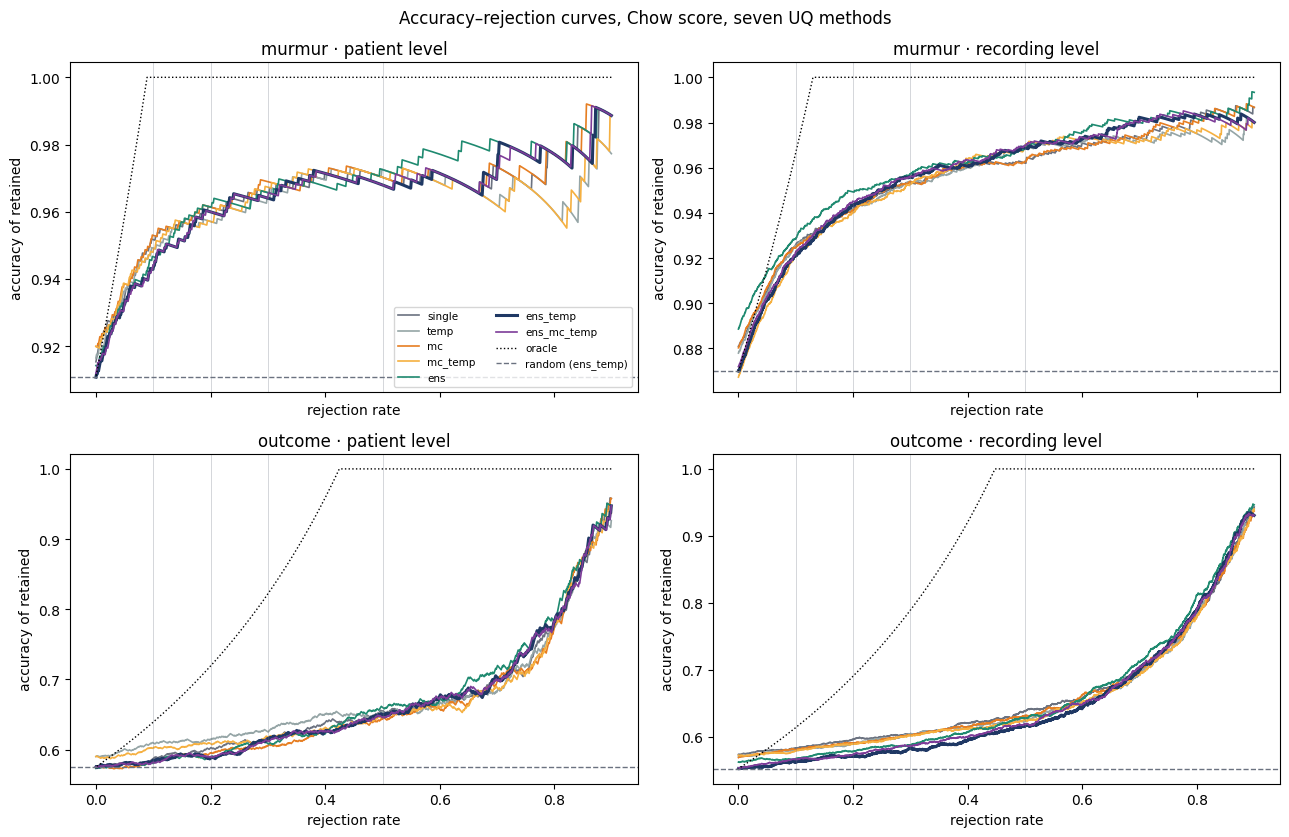

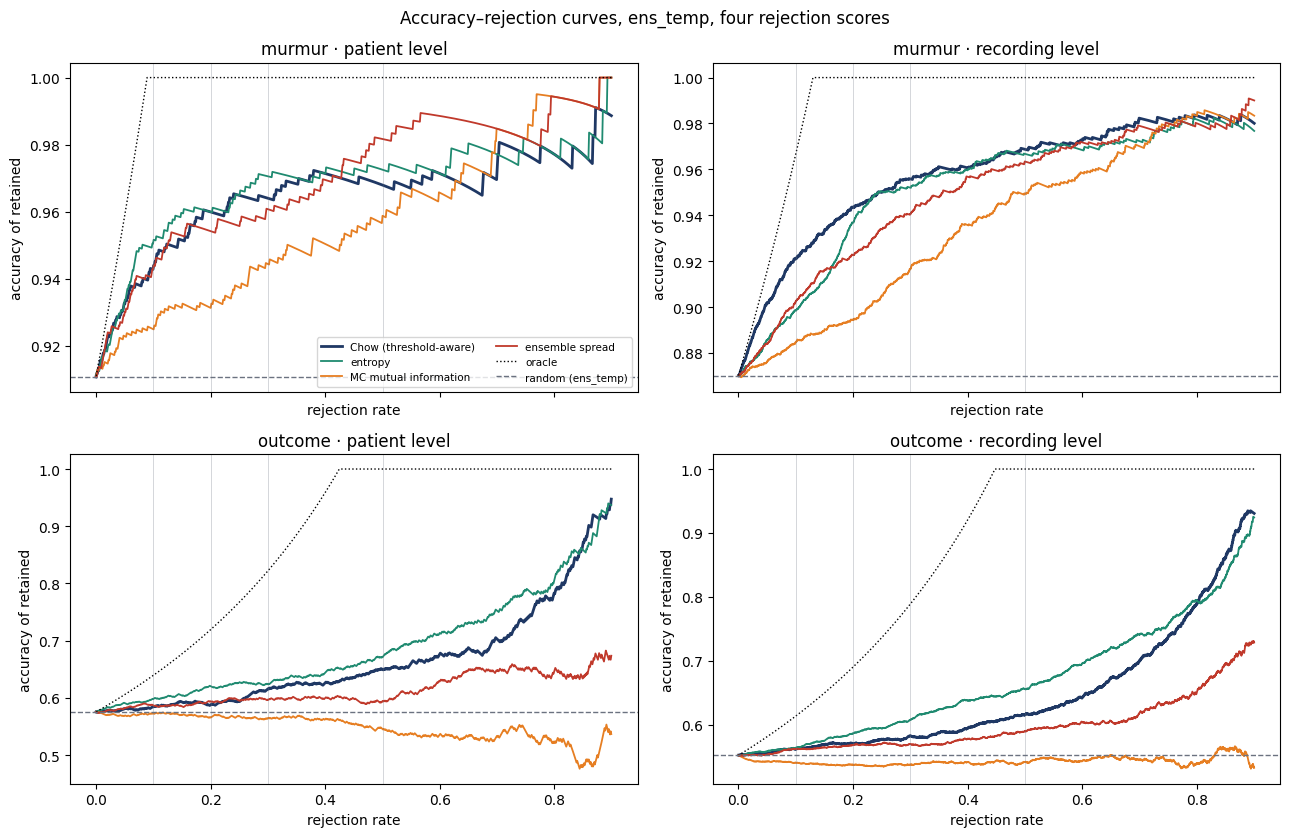

In [9]:
def risk_coverage(err, risk, tb):
    order = np.lexsort((tb, risk))                     # most confident first
    cum = np.cumsum(err[order]); j = np.arange(1, len(err) + 1)
    return j / len(err), cum / j                       # coverage, selective error rate

curve_rows = []
for lvl in LEVELS:
    for task in TASKS:
        idx = EVAL[(lvl, task)]
        for m, sc in COMBOS + [("oracle", "oracle")]:
            d = D[(lvl, task, PRIMARY if m == "oracle" else m)]
            err = 1 - d["correct"][idx]; tb = TIEB[lvl][idx]
            risk = err + 1e-9 * d["chow"][idx] if m == "oracle" else d[sc][idx]
            cov, sel = risk_coverage(err, risk, tb)
            keep = cov >= 1 - cfg.curve_max - 1e-12
            curve_rows.append(pd.DataFrame({"level": lvl, "task": task, "method": m, "score": sc,
                                            "rejection_rate": 1 - cov[keep], "accuracy_retained": 1 - sel[keep]}))
curves = pd.concat(curve_rows, ignore_index=True)

def plot_curves(sel_fn, title, fname):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
    for i, task in enumerate(TASKS):
        for j, lvl in enumerate(LEVELS):
            ax = axes[i, j]
            base = 1 - np.nanmean(1 - D[(lvl, task, PRIMARY)]["correct"][EVAL[(lvl, task)]])
            for (m, sc), style in sel_fn():
                c = curves[(curves.level == lvl) & (curves.task == task) & (curves.method == m) & (curves.score == sc)]
                ax.plot(c.rejection_rate, c.accuracy_retained, **style)
            o = curves[(curves.level == lvl) & (curves.task == task) & (curves.method == "oracle")]
            ax.plot(o.rejection_rate, o.accuracy_retained, color="black", ls=":", lw=1, label="oracle")
            ax.axhline(base, color=GRAY, ls="--", lw=1, label="random (ens_temp)")
            for r in cfg.rates:
                ax.axvline(r, color=GRAY, lw=0.4, alpha=0.5)
            ax.set(title=f"{task} · {lvl} level", xlabel="rejection rate", ylabel="accuracy of retained")
            if i == 0 and j == 0:
                ax.legend(fontsize=7.5, ncol=2)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=200); plt.show()

plot_curves(lambda: [((m, "chow"), dict(color=METHOD_COLOR[m], lw=2.2 if m == PRIMARY else 1.2, label=m)) for m in METHODS],
            "Accuracy–rejection curves, Chow score, seven UQ methods", "rq4_accuracy_rejection_methods.png")
plot_curves(lambda: [((PRIMARY, sc), dict(color=c, lw=2 if sc == "chow" else 1.3, label=SCORE_NAME[sc]))
                     for sc, c in [("chow", NAVY), ("entropy", TEAL), ("mi_mc", ORANGE), ("ens_std", RED)]],
            "Accuracy–rejection curves, ens_temp, four rejection scores", "rq4_accuracy_rejection_scores.png")

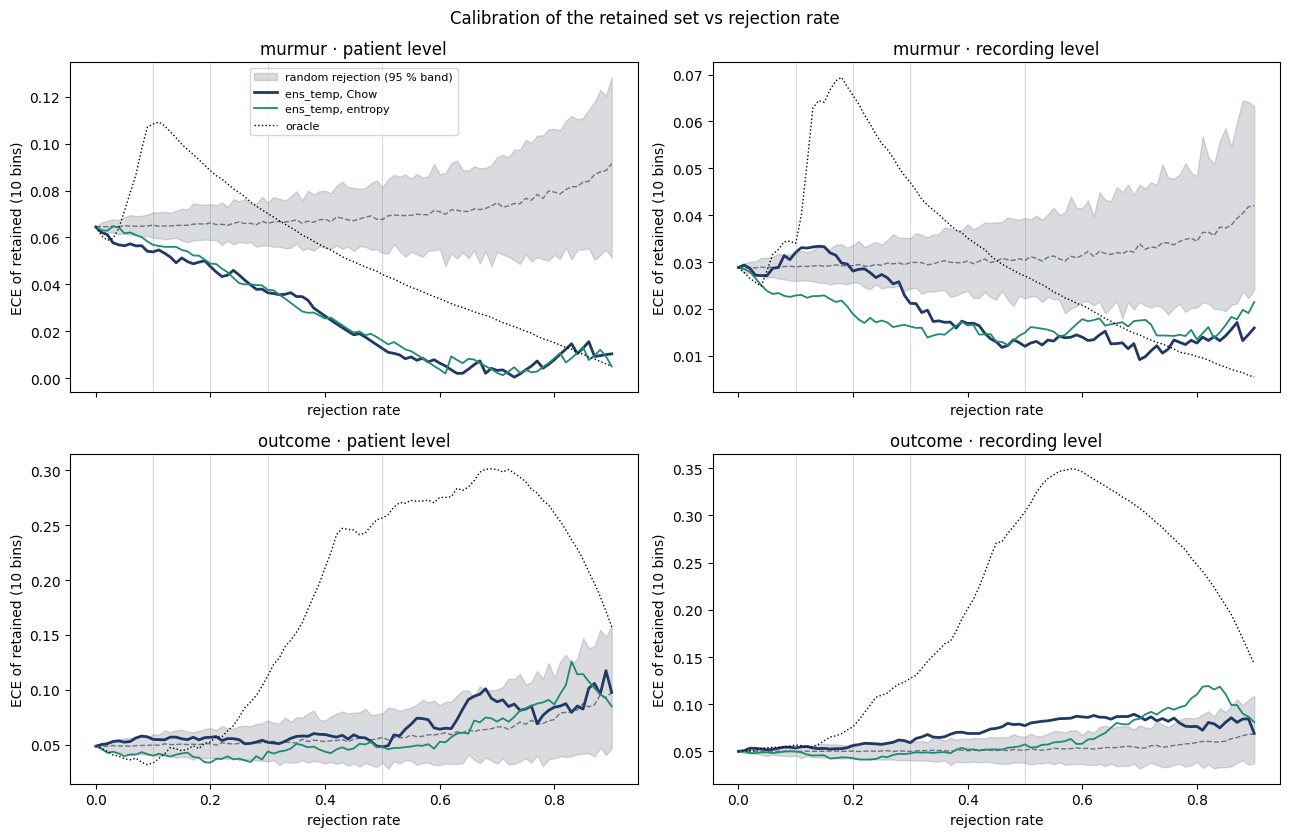

In [10]:
ECE_GRID = np.round(np.arange(0, cfg.curve_max + 1e-9, 0.01), 2)
rng_ece = np.random.default_rng(SEED + 1)
ece_rows = []
for lvl in LEVELS:
    for task in TASKS:
        idx = EVAL[(lvl, task)]; n = len(idx); tb = TIEB[lvl][idx]
        for m, sc in COMBOS:
            d = D[(lvl, task, m)]
            y, p, risk, corr = d["y"][idx], d["p"][idx], d[sc][idx], d["correct"][idx].astype(bool)
            for r in ECE_GRID:
                k = int(round(r * n)); kp = ~reject_mask(risk, tb, k)
                row = {"level": lvl, "task": task, "method": m, "score": sc, "rejection_rate": r, "ECE retained": ece_binary(y[kp], p[kp])}
                if sc == "chow":
                    keep_idx = rng_ece.random((200, n)).argsort(1)[:, :n - k]
                    rand = np.array([ece_binary(y[ix], p[ix]) for ix in keep_idx])
                    o = ~oracle_mask(corr, risk, tb, k)
                    row.update({"ECE random mean": rand.mean(), "ECE random lo": np.percentile(rand, 2.5),
                                "ECE random hi": np.percentile(rand, 97.5), "ECE oracle": ece_binary(y[o], p[o])})
                ece_rows.append(row)
ece_curves = pd.DataFrame(ece_rows)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
for i, task in enumerate(TASKS):
    for j, lvl in enumerate(LEVELS):
        ax = axes[i, j]
        c = ece_curves[(ece_curves.level == lvl) & (ece_curves.task == task) & (ece_curves.method == PRIMARY)]
        cc, ce = c[c.score == "chow"], c[c.score == "entropy"]
        ax.fill_between(cc.rejection_rate, cc["ECE random lo"], cc["ECE random hi"], color=GRAY, alpha=0.25, label="random rejection (95 % band)")
        ax.plot(cc.rejection_rate, cc["ECE random mean"], color=GRAY, ls="--", lw=1)
        ax.plot(cc.rejection_rate, cc["ECE retained"], color=NAVY, lw=2, label="ens_temp, Chow")
        ax.plot(ce.rejection_rate, ce["ECE retained"], color=TEAL, lw=1.3, label="ens_temp, entropy")
        ax.plot(cc.rejection_rate, cc["ECE oracle"], color="black", ls=":", lw=1, label="oracle")
        for r in cfg.rates:
            ax.axvline(r, color=GRAY, lw=0.4, alpha=0.5)
        ax.set(title=f"{task} · {lvl} level", xlabel="rejection rate", ylabel="ECE of retained (10 bins)")
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
fig.suptitle("Calibration of the retained set vs rejection rate"); plt.tight_layout()
plt.savefig(FIG_DIR / "rq4_ece_rejection.png", dpi=200); plt.show()

## 8. Analyses B, C, D, G — everything at the reporting rates (10 / 20 / 30 / 50 %), with paired bootstrap CIs

*Components: ④ UQ → confidence gate.*

For every level × task × method with the Chow score, plus `ens_temp` with entropy (the doc's literal measure):

- **B. Calibration:** ECE before, ECE retained, **Δ after − before**, ECE after random rejection of the same number, **Δ confidence − random**, ECE after oracle rejection.
- **C. Rejection cost:** share of rejected that were correct (random rejection would give the starting accuracy), share of correct predictions lost (random = the rate), share of errors removed (random = the rate), rejected false negatives / false positives.
- **D. Who's cut:** share of positives (Present / Abnormal) and negatives deferred (random = the rate), sensitivity and specificity retained; for murmur at patient level, share deferred per systolic grade.
- **G. Retained metrics:** F1, Accuracy, Weighted accuracy, AUC (+ cost for outcome), Sensitivity, Specificity, Precision, and their change from before rejection.

Each bootstrap resample re-ranks and re-rejects at the same rates; random rejection inside a resample is averaged over 20 draws (1,000 draws for the point estimate). This cell takes several minutes.

In [11]:
RATE_COMBOS = [(m, "chow") for m in METHODS] + [(PRIMARY, "entropy")]
rate_point, rate_boot = {}, {}
for lvl in LEVELS:
    for task in TASKS:
        idx = EVAL[(lvl, task)]; tb = TIEB[lvl][idx]
        grade = PAT.systolic_grade.values[idx] if (lvl == "patient" and task == "murmur") else None
        for m, sc in tqdm(RATE_COMBOS, desc=f"{task} · {lvl}"):
            d = D[(lvl, task, m)]
            y, p, yhat, risk = d["y"][idx], d["p"][idx], d["yhat"][idx], d[sc][idx]
            grp = {g: grade == g for g in GRADES} if grade is not None else None
            rng = np.random.default_rng(SEED + 7)
            rate_point[(lvl, task, m, sc)] = evaluate_at_rates(y, p, yhat, risk, tb, task, rng, cfg.n_random_point, grp)
            rate_boot[(lvl, task, m, sc)] = [evaluate_at_rates(y[b], p[b], yhat[b], risk[b], tb[b], task, rng, cfg.n_random_boot,
                                                               {g: mk[b] for g, mk in grp.items()} if grp else None)
                                             for b in BI[(lvl, task)]]
print("done")

murmur · patient:   0%|          | 0/8 [00:00<?, ?it/s]

outcome · patient:   0%|          | 0/8 [00:00<?, ?it/s]

murmur · recording:   0%|          | 0/8 [00:00<?, ?it/s]

outcome · recording:   0%|          | 0/8 [00:00<?, ?it/s]

done


In [12]:
rate_rows = []
for key, point in rate_point.items():
    lvl, task, m, sc = key
    boots = rate_boot[key]
    full_acc = point[0.0]["Accuracy"]
    for r in [0.0] + list(cfg.rates):
        for q, v in point[r].items():
            arr = np.array([bt[r].get(q, np.nan) for bt in boots], dtype=float)
            row = {"level": lvl, "task": task, "method": m, "score": sc, "rate": r, "quantity": q, "value": v,
                   "ci_low": np.nanpercentile(arr, 2.5), "ci_high": np.nanpercentile(arr, 97.5)}
            rate_rows.append(row)
            if r == 0.0:
                continue
            # paired differences, each against what it should be compared with
            refs = []
            if q in point[0.0]:                                   # retained metric vs before rejection
                refs.append(("change from before", point[0.0][q], np.array([bt[0.0][q] for bt in boots], dtype=float)))
            if q == "ECE":                                        # vs random rejection of the same number
                refs.append(("vs random rejection", point[r]["ECE random rejection"],
                             np.array([bt[r]["ECE random rejection"] for bt in boots], dtype=float)))
            if q == "share of rejected that were correct":        # random rejection removes correct cases at the starting accuracy
                refs.append(("vs random rejection", full_acc, np.array([bt[0.0]["Accuracy"] for bt in boots], dtype=float)))
            if q in ("share of correct predictions lost", "share of errors removed", "share of positives deferred",
                     "share of negatives deferred") or q.startswith("share deferred:"):
                refs.append(("vs random rejection", r, np.full(len(boots), r)))
            for name, ref_v, ref_arr in refs:
                dd = arr - ref_arr
                lo, hi = np.nanpercentile(dd, [2.5, 97.5])
                rate_rows.append({"level": lvl, "task": task, "method": m, "score": sc, "rate": r,
                                  "quantity": f"{q} — {name}", "value": v - ref_v, "ci_low": lo, "ci_high": hi})
rates_df = pd.DataFrame(rate_rows)
rates_df["is_difference"] = rates_df.quantity.str.contains(" — ")
rates_df["clear"] = rates_df.is_difference & ((rates_df.ci_low > 0) | (rates_df.ci_high < 0))
def cell(r):
    if r.quantity.startswith(("rejected false", "rejected correct")) and not r.is_difference:
        return f"{r.value:.0f}"
    if "Cost" in r.quantity:
        return (f"{r.value:+,.0f} [{r.ci_low:+,.0f}, {r.ci_high:+,.0f}]" if r.is_difference else f"{r.value:,.0f} [{r.ci_low:,.0f}, {r.ci_high:,.0f}]")
    return (fmt_dci if r.is_difference else fmt_ci)(r.value, r.ci_low, r.ci_high) + (" *" if r.clear else "")
rates_df["value (95% CI)"] = rates_df.apply(cell, axis=1)

def show(level, task, quantities, method=PRIMARY, score="chow"):
    s = rates_df[(rates_df.level == level) & (rates_df.task == task) & (rates_df.method == method) & (rates_df.score == score)
                 & rates_df.quantity.isin(quantities)]
    display(s.pivot_table(index="quantity", columns="rate", values="value (95% CI)", aggfunc="first").reindex(quantities))

B_Q = ["ECE", "ECE — change from before", "ECE random rejection", "ECE — vs random rejection", "ECE oracle rejection"]
C_Q = ["share of rejected that were correct", "share of rejected that were correct — vs random rejection", "rejected correct",
       "share of correct predictions lost", "share of correct predictions lost — vs random rejection",
       "share of errors removed", "share of errors removed — vs random rejection", "rejected false negatives", "rejected false positives"]
for task in TASKS:
    for lvl in LEVELS:
        print(f"\n===== {task.upper()} · {lvl} level · ens_temp, Chow  (* = 95% CI excludes 0) =====")
        print("B. Calibration"); show(lvl, task, B_Q)
        print("C. Rejection cost"); show(lvl, task, C_Q)
print("\nB. ΔECE vs random rejection, every method (Chow) and ens_temp with entropy, patient level:")
s = rates_df[(rates_df.level == "patient") & (rates_df.quantity == "ECE — vs random rejection")]
display(s.assign(m=s.method + " · " + s.score).pivot_table(index=["task", "m"], columns="rate", values="value (95% CI)", aggfunc="first"))


===== MURMUR · patient level · ens_temp, Chow  (* = 95% CI excludes 0) =====
B. Calibration


rate,0.0,0.1,0.2,0.3,0.5
quantity,,,,,
ECE,"0.065 [0.053, 0.084]","0.054 [0.045, 0.073]","0.048 [0.035, 0.066]","0.036 [0.026, 0.055]","0.013 [0.005, 0.031]"
ECE — change from before,NaN,"-0.011 [-0.018, -0.001] *","-0.017 [-0.029, -0.008] *","-0.028 [-0.041, -0.016] *","-0.052 [-0.066, -0.037] *"
ECE random rejection,NaN,"0.065 [0.054, 0.084]","0.066 [0.055, 0.085]","0.066 [0.055, 0.085]","0.069 [0.058, 0.087]"
ECE — vs random rejection,NaN,"-0.011 [-0.018, -0.002] *","-0.018 [-0.030, -0.009] *","-0.030 [-0.042, -0.018] *","-0.056 [-0.069, -0.041] *"
ECE oracle rejection,NaN,"0.108 [0.097, 0.117]","0.088 [0.081, 0.097]","0.070 [0.064, 0.077]","0.044 [0.040, 0.049]"


C. Rejection cost


rate,0.1,0.2,0.3,0.5
quantity,,,,
share of rejected that were correct,"0.621 [0.506, 0.713]","0.714 [0.636, 0.784]","0.786 [0.731, 0.833]","0.854 [0.818, 0.884]"
share of rejected that were correct — vs random rejection,"-0.290 [-0.391, -0.210] *","-0.196 [-0.260, -0.143] *","-0.124 [-0.164, -0.092] *","-0.057 [-0.077, -0.040] *"
rejected correct,54,125,206,373
share of correct predictions lost,"0.068 [0.057, 0.077]","0.157 [0.142, 0.169]","0.259 [0.245, 0.270]","0.469 [0.457, 0.479]"
share of correct predictions lost — vs random rejection,"-0.032 [-0.043, -0.023] *","-0.043 [-0.058, -0.031] *","-0.041 [-0.055, -0.030] *","-0.031 [-0.043, -0.021] *"
share of errors removed,"0.423 [0.345, 0.538]","0.641 [0.539, 0.744]","0.718 [0.625, 0.822]","0.821 [0.733, 0.909]"
share of errors removed — vs random rejection,"+0.323 [+0.245, +0.438] *","+0.441 [+0.339, +0.544] *","+0.418 [+0.325, +0.522] *","+0.321 [+0.233, +0.409] *"
rejected false negatives,7,16,21,24
rejected false positives,26,34,35,40



===== MURMUR · recording level · ens_temp, Chow  (* = 95% CI excludes 0) =====
B. Calibration


rate,0.0,0.1,0.2,0.3,0.5
quantity,,,,,
ECE,"0.029 [0.020, 0.043]","0.032 [0.021, 0.046]","0.028 [0.017, 0.043]","0.021 [0.011, 0.037]","0.012 [0.004, 0.026]"
ECE — change from before,NaN,"+0.003 [-0.004, +0.007]","-0.001 [-0.009, +0.005]","-0.008 [-0.017, -0.000] *","-0.017 [-0.027, -0.009] *"
ECE random rejection,NaN,"0.029 [0.021, 0.043]","0.029 [0.021, 0.043]","0.029 [0.022, 0.044]","0.031 [0.023, 0.045]"
ECE — vs random rejection,NaN,"+0.003 [-0.004, +0.007]","-0.001 [-0.009, +0.005]","-0.008 [-0.018, -0.001] *","-0.019 [-0.028, -0.011] *"
ECE oracle rejection,NaN,"0.034 [0.027, 0.052]","0.066 [0.058, 0.073]","0.047 [0.041, 0.054]","0.027 [0.024, 0.030]"


... (8 outputs left out)

C. Rejection cost


rate,0.1,0.2,0.3,0.5
quantity,,,,
share of rejected that were correct,"0.465 [0.409, 0.516]","0.479 [0.441, 0.521]","0.481 [0.455, 0.521]","0.489 [0.462, 0.517]"
share of rejected that were correct — vs random rejection,"-0.087 [-0.143, -0.039] *","-0.074 [-0.113, -0.031] *","-0.072 [-0.095, -0.033] *","-0.064 [-0.085, -0.042] *"
rejected correct,147,303,456,773
share of correct predictions lost,"0.084 [0.074, 0.093]","0.173 [0.160, 0.189]","0.261 [0.249, 0.282]","0.442 [0.424, 0.461]"
share of correct predictions lost — vs random rejection,"-0.016 [-0.026, -0.007] *","-0.027 [-0.040, -0.011] *","-0.039 [-0.051, -0.018] *","-0.058 [-0.076, -0.039] *"
share of errors removed,"0.119 [0.109, 0.133]","0.233 [0.214, 0.251]","0.348 [0.322, 0.366]","0.571 [0.546, 0.597]"
share of errors removed — vs random rejection,"+0.019 [+0.009, +0.033] *","+0.033 [+0.014, +0.051] *","+0.048 [+0.022, +0.066] *","+0.071 [+0.046, +0.097] *"
rejected false negatives,48,92,130,210
rejected false positives,121,238,363,599



B. ΔECE vs random rejection, every method (Chow) and ens_temp with entropy, patient level:


rate                                              0.1                        0.2                        0.3                        0.5
task    m                                                                                                                             
murmur  ens · chow            -0.009 [-0.017, +0.000]  -0.015 [-0.026, -0.005] *  -0.025 [-0.038, -0.015] *  -0.045 [-0.062, -0.033] *
        ens_mc_temp · chow  -0.012 [-0.018, -0.000] *  -0.021 [-0.031, -0.010] *  -0.031 [-0.043, -0.019] *  -0.053 [-0.069, -0.038] *
        ens_temp · chow     -0.011 [-0.018, -0.002] *  -0.018 [-0.030, -0.009] *  -0.030 [-0.042, -0.018] *  -0.056 [-0.069, -0.041] *
        ens_temp · entropy  -0.008 [-0.017, -0.000] *  -0.017 [-0.029, -0.008] *  -0.029 [-0.042, -0.019] *  -0.053 [-0.068, -0.039] *
        mc · chow           -0.010 [-0.020, -0.002] *  -0.023 [-0.036, -0.013] *  -0.034 [-0.047, -0.022] *  -0.063 [-0.079, -0.050] *
        mc_temp · chow      -0.014 [-0.022, -0.005] *  -0.029 [-0.041, -0.018] *  -0.043 [-0.057, -0.032] *  -0.067 [-0.082, -0.052] *
        single · chow       -0.011 [-0.021, -0.003] *  -0.023 [-0.036, -0.014] *  -0.034 [-0.047, -0.021] *  -0.063 [-0.079, -0.049] *
        temp · chow         -0.014 [-0.023, -0.005] *  -0.028 [-0.040, -0.018] *  -0.043 [-0.056, -0.031] *  -0.064 [-0.080, -0.050] *
outcome ens · chow            +0.002 [-0.007, +0.013]    +0.003 [-0.011, +0.019]    +0.000 [-0.013, +0.026]    +0.004 [-0.021, +0.037]
        ens_mc_temp · chow    +0.012 [-0.004, +0.020]    +0.004 [-0.010, +0.020]    +0.003 [-0.015, +0.025]    -0.001 [-0.017, +0.037]
        ens_temp · chow       +0.005 [-0.006, +0.017]    +0.006 [-0.008, +0.021]    -0.000 [-0.016, +0.023]    -0.008 [-0.020, +0.035]
        ens_temp · entropy    -0.010 [-0.017, +0.008]    -0.017 [-0.024, +0.012]    -0.008 [-0.025, +0.017]    -0.008 [-0.027, +0.029]
        mc · chow             +0.007 [-0.003, +0.018]    -0.001 [-0.009, +0.022]    +0.005 [-0.011, +0.033]    +0.030 [-0.000, +0.060]
        mc_temp · chow        -0.001 [-0.009, +0.015]    +0.002 [-0.010, +0.020]    +0.004 [-0.011, +0.032]  +0.026 [+0.001, +0.061] *
        single · chow         +0.000 [-0.008, +0.014]    -0.001 [-0.014, +0.022]    -0.000 [-0.014, +0.027]    +0.024 [-0.006, +0.054]
        temp · chow           +0.004 [-0.007, +0.013]    +0.007 [-0.008, +0.022]    +0.007 [-0.013, +0.033]  +0.028 [+0.001, +0.057] *

In [13]:
D_Q = ["share of positives deferred", "share of positives deferred — vs random rejection",
       "share of negatives deferred", "share of negatives deferred — vs random rejection",
       "Sensitivity", "Sensitivity — change from before", "Specificity", "Specificity — change from before"]
G_Q = {"murmur": ["F1 (macro)", "Accuracy", "Weighted accuracy", "AUC", "Precision"],
       "outcome": ["F1 (macro)", "Accuracy", "Weighted accuracy", "AUC", "Cost (c_outcome)", "Precision"]}
for task in TASKS:
    for lvl in LEVELS:
        print(f"\n===== {task.upper()} · {lvl} level · ens_temp, Chow — positives = {POS_NAME[task][0]} =====")
        print("D. Who's cut: class mix"); show(lvl, task, D_Q)
        gq = [q for g in G_Q[task] for q in (g, f"{g} — change from before")]
        print("G. Metrics of the retained set"); show(lvl, task, gq)
print("\nD. Who's cut: murmur grade (Present patients, patient level, ens_temp, Chow; random rejection = the rate)")
gq = [q for g in GRADES for q in (f"share deferred: {g}", f"share deferred: {g} — vs random rejection")]
show("patient", "murmur", gq)
print("n Present patients per grade:", PAT[PAT.murmur == "Present"].systolic_grade.value_counts().to_dict())


===== MURMUR · patient level · ens_temp, Chow — positives = Present =====
D. Who's cut: class mix


rate,0.0,0.1,0.2,0.3,0.5
quantity,,,,,
share of positives deferred,NaN,"0.112 [0.076, 0.157]","0.207 [0.153, 0.267]","0.296 [0.240, 0.360]","0.374 [0.308, 0.446]"
share of positives deferred — vs random rejection,NaN,"+0.012 [-0.024, +0.057]","+0.007 [-0.047, +0.067]","-0.004 [-0.060, +0.060]","-0.126 [-0.192, -0.054] *"
share of negatives deferred,NaN,"0.096 [0.085, 0.106]","0.199 [0.184, 0.212]","0.301 [0.285, 0.315]","0.532 [0.514, 0.552]"
share of negatives deferred — vs random rejection,NaN,"-0.004 [-0.015, +0.006]","-0.001 [-0.016, +0.012]","+0.001 [-0.015, +0.015]","+0.032 [+0.014, +0.052] *"
Sensitivity,"0.799 [0.731, 0.858]","0.818 [0.758, 0.887]","0.859 [0.794, 0.918]","0.881 [0.816, 0.939]","0.893 [0.833, 0.952]"
Sensitivity — change from before,NaN,"+0.019 [-0.003, +0.056]","+0.060 [+0.021, +0.100] *","+0.082 [+0.037, +0.134] *","+0.094 [+0.047, +0.152] *"
Specificity,"0.940 [0.920, 0.955]","0.975 [0.961, 0.987]","0.986 [0.974, 0.995]","0.986 [0.975, 0.996]","0.994 [0.985, 1.000]"
Specificity — change from before,NaN,"+0.035 [+0.023, +0.048] *","+0.046 [+0.031, +0.064] *","+0.046 [+0.031, +0.065] *","+0.054 [+0.038, +0.074] *"


G. Metrics of the retained set


rate,0.0,0.1,0.2,0.3,0.5
quantity,,,,,
F1 (macro),"0.865 [0.835, 0.893]","0.908 [0.881, 0.937]","0.936 [0.909, 0.959]","0.944 [0.918, 0.968]","0.957 [0.932, 0.979]"
F1 (macro) — change from before,NaN,"+0.044 [+0.031, +0.062] *","+0.071 [+0.052, +0.094] *","+0.079 [+0.058, +0.104] *","+0.092 [+0.067, +0.121] *"
Accuracy,"0.911 [0.891, 0.929]","0.943 [0.924, 0.960]","0.960 [0.944, 0.974]","0.964 [0.949, 0.979]","0.968 [0.950, 0.984]"
Accuracy — change from before,NaN,"+0.032 [+0.023, +0.043] *","+0.049 [+0.036, +0.065] *","+0.053 [+0.039, +0.070] *","+0.057 [+0.040, +0.077] *"
Weighted accuracy,"0.860 [0.823, 0.894]","0.887 [0.853, 0.928]","0.915 [0.879, 0.949]","0.927 [0.892, 0.961]","0.930 [0.892, 0.968]"
Weighted accuracy — change from before,NaN,"+0.026 [+0.014, +0.047] *","+0.054 [+0.030, +0.079] *","+0.066 [+0.040, +0.098] *","+0.070 [+0.040, +0.106] *"
AUC,"0.925 [0.896, 0.954]","0.932 [0.900, 0.962]","0.937 [0.903, 0.968]","0.940 [0.904, 0.972]","0.955 [0.920, 0.982]"
AUC — change from before,NaN,"+0.007 [+0.002, +0.012] *","+0.012 [+0.002, +0.020] *","+0.015 [+0.003, +0.026] *","+0.030 [+0.013, +0.045] *"
Precision,"0.773 [0.707, 0.833]","0.890 [0.835, 0.943]","0.938 [0.889, 0.979]","0.941 [0.893, 0.983]","0.980 [0.952, 1.000]"



===== MURMUR · recording level · ens_temp, Chow — positives = Present =====
D. Who's cut: class mix


rate,0.0,0.1,0.2,0.3,0.5
quantity,,,,,
share of positives deferred,NaN,"0.096 [0.072, 0.126]","0.214 [0.178, 0.248]","0.343 [0.293, 0.392]","0.479 [0.418, 0.539]"
share of positives deferred — vs random rejection,NaN,"-0.004 [-0.028, +0.026]","+0.014 [-0.022, +0.048]","+0.043 [-0.007, +0.092]","-0.021 [-0.082, +0.039]"
share of negatives deferred,NaN,"0.101 [0.094, 0.107]","0.196 [0.188, 0.206]","0.289 [0.277, 0.302]","0.506 [0.490, 0.522]"
share of negatives deferred — vs random rejection,NaN,"+0.001 [-0.006, +0.007]","-0.004 [-0.012, +0.006]","-0.011 [-0.023, +0.002]","+0.006 [-0.010, +0.022]"
Sensitivity,"0.768 [0.712, 0.819]","0.765 [0.702, 0.819]","0.779 [0.711, 0.835]","0.802 [0.733, 0.864]","0.869 [0.801, 0.921]"
Sensitivity — change from before,NaN,"-0.003 [-0.015, +0.009]","+0.011 [-0.009, +0.029]","+0.035 [+0.008, +0.059] *","+0.101 [+0.064, +0.138] *"
Specificity,"0.896 [0.879, 0.912]","0.961 [0.948, 0.973]","0.985 [0.977, 0.992]","0.992 [0.987, 0.997]","0.996 [0.992, 0.999]"
Specificity — change from before,NaN,"+0.065 [+0.056, +0.074] *","+0.089 [+0.077, +0.101] *","+0.096 [+0.082, +0.111] *","+0.099 [+0.085, +0.116] *"


... (9 outputs left out)

rate,0.0,0.1,0.2,0.3,0.5
quantity,,,,,
F1 (macro),"0.533 [0.509, 0.559]","0.539 [0.513, 0.567]","0.544 [0.515, 0.574]","0.549 [0.512, 0.579]","0.561 [0.526, 0.601]"
F1 (macro) — change from before,NaN,"+0.006 [+0.000, +0.012] *","+0.011 [-0.001, +0.021]","+0.016 [-0.002, +0.027]","+0.027 [+0.005, +0.050] *"
Accuracy,"0.552 [0.524, 0.581]","0.562 [0.534, 0.591]","0.571 [0.539, 0.602]","0.583 [0.545, 0.615]","0.616 [0.578, 0.656]"
Accuracy — change from before,NaN,"+0.010 [+0.004, +0.016] *","+0.018 [+0.008, +0.028] *","+0.031 [+0.014, +0.041] *","+0.064 [+0.042, +0.085] *"
Weighted accuracy,"0.702 [0.673, 0.728]","0.716 [0.685, 0.744]","0.729 [0.695, 0.760]","0.744 [0.705, 0.774]","0.783 [0.748, 0.818]"
Weighted accuracy — change from before,NaN,"+0.014 [+0.008, +0.021] *","+0.027 [+0.016, +0.036] *","+0.042 [+0.028, +0.052] *","+0.081 [+0.066, +0.099] *"
AUC,"0.640 [0.604, 0.673]","0.650 [0.614, 0.683]","0.663 [0.626, 0.698]","0.675 [0.636, 0.711]","0.717 [0.675, 0.756]"
AUC — change from before,NaN,"+0.009 [+0.003, +0.014] *","+0.023 [+0.014, +0.031] *","+0.035 [+0.022, +0.047] *","+0.076 [+0.057, +0.097] *"
Cost (c_outcome),"11,551 [10,718, 12,433]","11,610 [10,806, 12,472]","11,684 [10,828, 12,562]","11,963 [11,122, 12,890]","12,557 [11,612, 13,504]"



D. Who's cut: murmur grade (Present patients, patient level, ens_temp, Chow; random rejection = the rate)


rate,0.1,0.2,0.3,0.5
quantity,,,,
share deferred: grade I,"0.183 [0.127, 0.264]","0.346 [0.263, 0.430]","0.452 [0.366, 0.544]","0.548 [0.458, 0.638]"
share deferred: grade I — vs random rejection,"+0.083 [+0.027, +0.164] *","+0.146 [+0.063, +0.230] *","+0.152 [+0.066, +0.244] *","+0.048 [-0.042, +0.138]"
share deferred: grade II,"0.036 [0.000, 0.118]","0.036 [0.000, 0.125]","0.143 [0.032, 0.300]","0.286 [0.129, 0.467]"
share deferred: grade II — vs random rejection,"-0.064 [-0.100, +0.018]","-0.164 [-0.200, -0.075] *","-0.157 [-0.268, +0.000]","-0.214 [-0.371, -0.033] *"
share deferred: grade III,"0.000 [0.000, 0.000]","0.000 [0.000, 0.043]","0.022 [0.000, 0.076]","0.022 [0.000, 0.076]"
share deferred: grade III — vs random rejection,"-0.100 [-0.100, -0.100] *","-0.200 [-0.200, -0.157] *","-0.278 [-0.300, -0.224] *","-0.478 [-0.500, -0.424] *"
share deferred: no systolic grade,"0.000 [0.000, 0.000]","0.000 [0.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]"
share deferred: no systolic grade — vs random rejection,"-0.100 [-0.100, -0.100] *","-0.200 [-0.200, +0.800]","+0.700 [+0.700, +0.700] *","+0.500 [+0.500, +0.500] *"


n Present patients per grade: {'grade I': 104, 'grade III': 46, 'grade II': 28, 'no systolic grade': 1}


## 9. Reliability diagrams before and after 20 % rejection

*Components: ④ UQ.*

`ens_temp`, patient level: observed frequency of the positive class against mean predicted probability in each of the 10 bins, for all patients and for the 80 % retained after Chow rejection. Marker size ∝ patients in the bin.

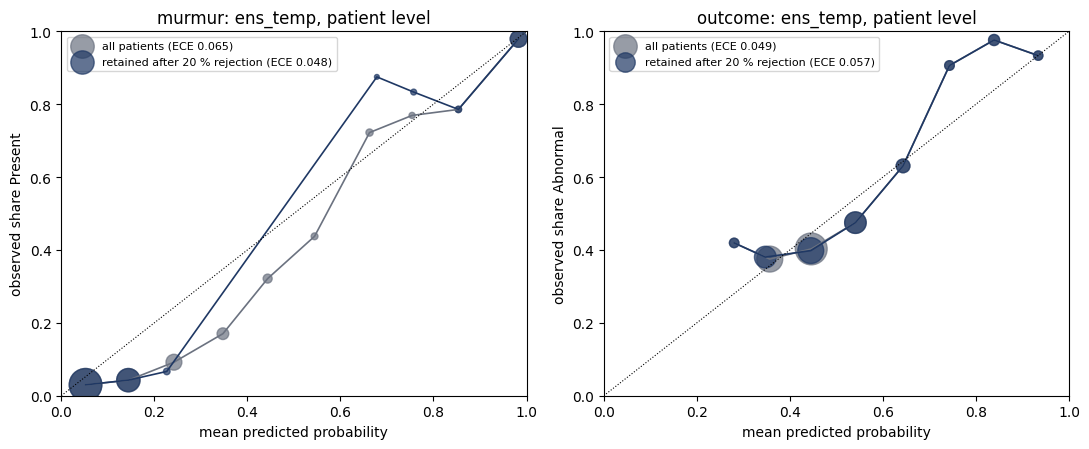

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, task in zip(axes, TASKS):
    idx = EVAL[("patient", task)]; d = D[("patient", task, PRIMARY)]
    y, p, risk, tb = d["y"][idx], d["p"][idx], d["chow"][idx], TIEB["patient"][idx]
    keep = ~reject_mask(risk, tb, int(round(0.2 * len(idx))))
    for mask, lab, col in [(np.ones(len(idx), bool), "all patients", GRAY), (keep, "retained after 20 % rejection", NAVY)]:
        b = np.minimum((p[mask] * 10).astype(int), 9)
        xs = [p[mask][b == k].mean() for k in range(10) if np.any(b == k)]
        ys = [y[mask][b == k].mean() for k in range(10) if np.any(b == k)]
        ns = [np.sum(b == k) for k in range(10) if np.any(b == k)]
        ax.plot(xs, ys, "-", color=col, lw=1.2)
        ax.scatter(xs, ys, s=np.array(ns) * 1.5, color=col, alpha=0.7, label=f"{lab} (ECE {ece_binary(y[mask], p[mask]):.3f})")
    ax.plot([0, 1], [0, 1], color="black", lw=0.8, ls=":")
    ax.set(title=f"{task}: ens_temp, patient level", xlabel="mean predicted probability", ylabel=f"observed share {POS_NAME[task][0]}",
           xlim=(0, 1), ylim=(0, 1)); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIG_DIR / "rq4_reliability_20.png", dpi=200); plt.show()

## 10. Analysis E — are Unknown-murmur patients the ones the gate defers?

*Components: ④ UQ × clinical ambiguity.*

Clinicians could not call a murmur for 68 patients (Unknown). They have no murmur correctness, so they are outside the curves; here the murmur gate's cutoffs (set on labelled patients at each rate) are applied to them. If the gate captures clinical ambiguity, it should defer **more** Unknown patients than the rate. Bootstrap over patient groups (both labelled and Unknown units resampled together, cutoff recomputed in each resample).

In [15]:
unk_rows = []
for lvl in LEVELS:
    for m, sc in [(PRIMARY, "chow"), (PRIMARY, "entropy")]:
        d = D[(lvl, "murmur", m)]
        lab, risk, tb = d["labelled"], d[sc], TIEB[lvl]
        def share_unknown(ix, r):
            l, u = ix[lab[ix]], ix[~lab[ix]]
            k = int(round(r * len(l)))
            if k == 0 or len(u) == 0:
                return np.nan
            order = l[np.lexsort((tb[l], -risk[l]))]
            cut = risk[order[k - 1]]                         # risk of the last rejected labelled unit
            return np.mean(risk[u] >= cut)
        full = np.arange(len(lab))
        for r in cfg.rates:
            v = share_unknown(full, r)
            arr = np.array([share_unknown(b, r) for b in BI_FULL[lvl]])
            lo, hi = np.nanpercentile(arr, [2.5, 97.5]); dlo, dhi = np.nanpercentile(arr - r, [2.5, 97.5])
            unk_rows.append({"level": lvl, "score": sc, "rate": r, "n_unknown": int((~lab).sum()), "share Unknown deferred": v,
                             "ci_low": lo, "ci_high": hi, "Δ vs rate": v - r, "Δ_lo": dlo, "Δ_hi": dhi})
unknown = pd.DataFrame(unk_rows)
unknown["share Unknown deferred (95% CI)"] = [fmt_ci(r_["share Unknown deferred"], r_["ci_low"], r_["ci_high"]) for _, r_ in unknown.iterrows()]
unknown["Δ vs rate (95% CI)"] = [fmt_dci(r_["Δ vs rate"], r_["Δ_lo"], r_["Δ_hi"]) for _, r_ in unknown.iterrows()]
display(unknown[["level", "score", "rate", "n_unknown", "share Unknown deferred (95% CI)", "Δ vs rate (95% CI)"]])

,level,score,rate,n_unknown,share Unknown deferred (95% CI),Δ vs rate (95% CI)
0,patient,chow,0.1,68,"0.176 [0.062, 0.261]","+0.076 [-0.038, +0.161]"
1,patient,chow,0.2,68,"0.265 [0.143, 0.375]","+0.065 [-0.057, +0.175]"
2,patient,chow,0.3,68,"0.441 [0.303, 0.583]","+0.141 [+0.003, +0.283]"
3,patient,chow,0.5,68,"0.779 [0.656, 0.873]","+0.279 [+0.156, +0.373]"
4,patient,entropy,0.1,68,"0.118 [0.046, 0.208]","+0.018 [-0.054, +0.108]"
5,patient,entropy,0.2,68,"0.309 [0.175, 0.413]","+0.109 [-0.025, +0.213]"
6,patient,entropy,0.3,68,"0.412 [0.305, 0.578]","+0.112 [+0.005, +0.278]"
7,patient,entropy,0.5,68,"0.779 [0.614, 0.887]","+0.279 [+0.114, +0.387]"
8,recording,chow,0.1,156,"0.167 [0.101, 0.230]","+0.067 [+0.001, +0.130]"
9,recording,chow,0.2,156,"0.378 [0.282, 0.458]","+0.178 [+0.082, +0.258]"


## 11. Analysis F — which method and score reject best? AUROC and AURC

*Components: ④ UQ (method comparison).*

- **AUROC** (methods document): how well the risk score separates incorrect from correct decisions (0.5 = no better than random rejection).
- **AURC** (area under the risk–coverage curve): mean error rate of the retained set over all coverages; lower is better. Unlike AUROC it also reflects how accurate the method is to begin with.
- Paired differences vs the primary (`ens_temp`, Chow), and Chow − entropy within each method.


===== patient level =====


AURC (95% CI)                                 AUROC (95% CI)                      
task                                    murmur                  outcome                murmur               outcome
m                                                                                                                  
ens · chow             0.0297 [0.0182, 0.0431]  0.3077 [0.2698, 0.3459]  0.798 [0.741, 0.854]  0.621 [0.585, 0.658]
ens · entropy          0.0266 [0.0160, 0.0390]  0.2909 [0.2556, 0.3296]  0.820 [0.765, 0.871]  0.655 [0.622, 0.688]
ens_mc_temp · chow     0.0319 [0.0192, 0.0457]  0.3117 [0.2736, 0.3499]  0.794 [0.732, 0.850]  0.612 [0.576, 0.648]
ens_mc_temp · entropy  0.0288 [0.0175, 0.0422]  0.2913 [0.2564, 0.3312]  0.815 [0.755, 0.869]  0.653 [0.618, 0.686]
ens_temp · chow        0.0320 [0.0193, 0.0463]  0.3116 [0.2737, 0.3498]  0.797 [0.734, 0.854]  0.612 [0.576, 0.647]
ens_temp · ens_std     0.0271 [0.0178, 0.0389]  0.3818 [0.3402, 0.4277]  0.812 [0.762, 0.858]  0.555 [0.516, 0.591]
ens_temp · entropy     0.0290 [0.0177, 0.0430]  0.2906 [0.2566, 0.3298]  0.817 [0.758, 0.871]  0.655 [0.621, 0.688]
ens_temp · mi_mc       0.0393 [0.0278, 0.0528]  0.4587 [0.4131, 0.5048]  0.716 [0.659, 0.770]  0.464 [0.427, 0.501]
mc · chow              0.0318 [0.0189, 0.0455]  0.3151 [0.2786, 0.3554]  0.780 [0.715, 0.841]  0.605 [0.569, 0.640]
mc · entropy           0.0316 [0.0187, 0.0453]  0.2952 [0.2592, 0.3339]  0.782 [0.720, 0.842]  0.643 [0.608, 0.677]
mc_temp · chow         0.0350 [0.0204, 0.0515]  0.3109 [0.2733, 0.3500]  0.769 [0.703, 0.834]  0.592 [0.556, 0.630]
mc_temp · entropy      0.0348 [0.0202, 0.0514]  0.2856 [0.2496, 0.3227]  0.771 [0.704, 0.837]  0.640 [0.605, 0.676]
single · chow          0.0322 [0.0194, 0.0462]  0.3105 [0.2734, 0.3491]  0.791 [0.732, 0.853]  0.619 [0.582, 0.656]
single · entropy       0.0318 [0.0190, 0.0458]  0.2924 [0.2558, 0.3295]  0.795 [0.736, 0.855]  0.650 [0.615, 0.683]
temp · chow            0.0353 [0.0210, 0.0515]  0.3048 [0.2673, 0.3430]  0.777 [0.712, 0.841]  0.609 [0.573, 0.645]
temp · entropy         0.0349 [0.0208, 0.0510]  0.2836 [0.2471, 0.3206]  0.782 [0.716, 0.846]  0.645 [0.610, 0.680]

Δ AURC (95% CI)                                         Δ AUROC (95% CI)                           
task                                                            murmur                       outcome                     murmur                    outcome
comparison                                                                                                                                                
ens · chow vs ens_temp · Chow               -0.0023 [-0.0052, +0.0011]  -0.0039 [-0.0075, -0.0003] *    +0.001 [-0.018, +0.018]    +0.009 [-0.010, +0.029]
ens · entropy vs ens_temp · Chow          -0.0054 [-0.0096, -0.0010] *  -0.0208 [-0.0404, -0.0011] *  +0.023 [+0.001, +0.043] *  +0.043 [+0.002, +0.085] *
ens: Chow − entropy                       +0.0031 [+0.0011, +0.0051] *    +0.0169 [-0.0029, +0.0353]  -0.022 [-0.036, -0.008] *    -0.034 [-0.072, +0.006]
ens_mc_temp · chow vs ens_temp · Chow       -0.0002 [-0.0007, +0.0004]    +0.0000 [-0.0009, +0.0009]    -0.003 [-0.012, +0.002]    -0.000 [-0.009, +0.008]
ens_mc_temp · entropy vs ens_temp · Chow  -0.0033 [-0.0052, -0.0012] *    -0.0203 [-0.0400, +0.0003]  +0.018 [+0.003, +0.033] *  +0.041 [+0.000, +0.082] *
ens_mc_temp: Chow − entropy               +0.0031 [+0.0012, +0.0050] *    +0.0203 [-0.0004, +0.0401]  -0.021 [-0.034, -0.008] *  -0.041 [-0.080, -0.000] *
ens_temp · ens_std vs ens_temp · Chow       -0.0049 [-0.0122, +0.0018]  +0.0701 [+0.0337, +0.1065] *    +0.015 [-0.027, +0.055]  -0.057 [-0.107, -0.005] *
ens_temp · entropy vs ens_temp · Chow     -0.0030 [-0.0048, -0.0010] *  -0.0211 [-0.0409, -0.0011] *  +0.020 [+0.008, +0.033] *  +0.043 [+0.004, +0.084] *
ens_temp · mi_mc vs ens_temp · Chow         +0.0072 [-0.0028, +0.0174]  +0.1470 [+0.1050, +0.1862] *  -0.081 [-0.149, -0.018] *  -0.148 [-0.205, -0.091] *
ens_temp: Chow − entropy                  +0.0030 [+0.0010, +0.0048] *  +0.0211 [+0.0011, +0.0409] *  -0.020 [-0.033, -0.008] *  -0.043 [-0.084, -0.004] *
mc · chow vs ens_temp · Chow                -0.0002 [-0.0050, +0.0054]    +0.0035 [-0.0058, +0.0131]    -0.017 [-0.057, +0.020]    -0.007 [-0.041, +0.027]
mc · entropy vs ens_temp · Chow             -0.0005 [-0.0056, +0.0054]    -0.0164 [-0.0381, +0.0061]    -0.014 [-0.056, +0.022]    +0.031 [-0.013, +0.074]
mc: Chow − entropy                          +0.0002 [-0.0004, +0.0009]    +0.0199 [-0.0010, +0.0414]    -0.002 [-0.007, +0.002]    -0.038 [-0.082, +0.007]
mc_temp · chow vs ens_temp · Chow           +0.0030 [-0.0017, +0.0081]    -0.0008 [-0.0091, +0.0080]    -0.028 [-0.070, +0.008]    -0.020 [-0.056, +0.015]
mc_temp · entropy vs ens_temp · Chow        +0.0028 [-0.0020, +0.0080]  -0.0260 [-0.0480, -0.0033] *    -0.026 [-0.067, +0.010]    +0.028 [-0.016, +0.071]
mc_temp: Chow − entropy                     +0.0002 [-0.0004, +0.0007]  +0.0252 [+0.0039, +0.0467] *    -0.003 [-0.007, +0.002]  -0.048 [-0.091, -0.005] *
single · chow vs ens_temp · Chow            +0.0002 [-0.0045, +0.0055]    -0.0011 [-0.0105, +0.0091]    -0.006 [-0.045, +0.030]    +0.007 [-0.027, +0.042]
single · entropy vs ens_temp · Chow         -0.0002 [-0.0051, +0.0055]    -0.0193 [-0.0411, +0.0036]    -0.002 [-0.043, +0.034]    +0.038 [-0.006, +0.080]
single: Chow − entropy                      +0.0004 [-0.0003, +0.0012]    +0.0181 [-0.0021, +0.0370]    -0.003 [-0.008, +0.002]    -0.030 [-0.069, +0.013]
temp · chow vs ens_temp · Chow              +0.0032 [-0.0013, +0.0080]    -0.0069 [-0.0149, +0.0015]    -0.020 [-0.057, +0.013]    -0.003 [-0.037, +0.031]
temp · entropy vs ens_temp · Chow           +0.0029 [-0.0017, +0.0080]  -0.0281 [-0.0501, -0.0054] *    -0.015 [-0.052, +0.018]    +0.033 [-0.011, +0.074]
temp: Chow − entropy                        +0.0003 [-0.0002, +0.0009]  +0.0212 [+0.0021, +0.0404] *  -0.005 [-0.010, -0.000] *    -0.036 [-0.074, +0.003]


===== recording level =====


AURC (95% CI)                                 AUROC (95% CI)                      
task                                    murmur                  outcome                murmur               outcome
m                                                                                                                  
ens · chow             0.0350 [0.0249, 0.0471]  0.3197 [0.2847, 0.3562]  0.819 [0.784, 0.852]  0.610 [0.582, 0.636]
ens · entropy          0.0365 [0.0263, 0.0490]  0.2983 [0.2663, 0.3323]  0.810 [0.771, 0.846]  0.659 [0.630, 0.690]
ens_mc_temp · chow     0.0389 [0.0282, 0.0517]  0.3264 [0.2900, 0.3626]  0.839 [0.804, 0.868]  0.615 [0.588, 0.642]
ens_mc_temp · entropy  0.0451 [0.0331, 0.0594]  0.3096 [0.2769, 0.3437]  0.805 [0.769, 0.838]  0.653 [0.624, 0.682]
ens_temp · chow        0.0392 [0.0287, 0.0518]  0.3290 [0.2925, 0.3652]  0.839 [0.806, 0.869]  0.610 [0.582, 0.638]
ens_temp · ens_std     0.0463 [0.0359, 0.0581]  0.3889 [0.3549, 0.4210]  0.791 [0.759, 0.819]  0.558 [0.534, 0.580]
ens_temp · entropy     0.0450 [0.0336, 0.0590]  0.3088 [0.2764, 0.3435]  0.807 [0.771, 0.840]  0.655 [0.627, 0.686]
ens_temp · mi_mc       0.0590 [0.0467, 0.0717]  0.4538 [0.4182, 0.4886]  0.717 [0.690, 0.747]  0.478 [0.453, 0.505]
mc · chow              0.0399 [0.0291, 0.0525]  0.3180 [0.2816, 0.3549]  0.815 [0.778, 0.849]  0.610 [0.583, 0.637]
mc · entropy           0.0394 [0.0281, 0.0526]  0.3043 [0.2716, 0.3379]  0.820 [0.783, 0.856]  0.645 [0.615, 0.676]
mc_temp · chow         0.0420 [0.0304, 0.0551]  0.3219 [0.2839, 0.3589]  0.837 [0.803, 0.867]  0.597 [0.569, 0.624]
mc_temp · entropy      0.0480 [0.0352, 0.0628]  0.3019 [0.2689, 0.3368]  0.809 [0.769, 0.843]  0.646 [0.616, 0.677]
single · chow          0.0397 [0.0290, 0.0524]  0.3165 [0.2800, 0.3541]  0.813 [0.777, 0.848]  0.607 [0.580, 0.633]
single · entropy       0.0389 [0.0276, 0.0521]  0.2984 [0.2659, 0.3329]  0.820 [0.783, 0.857]  0.649 [0.619, 0.680]
temp · chow            0.0416 [0.0301, 0.0551]  0.3211 [0.2836, 0.3582]  0.818 [0.783, 0.853]  0.602 [0.574, 0.629]
temp · entropy         0.0448 [0.0323, 0.0592]  0.3013 [0.2683, 0.3360]  0.804 [0.764, 0.840]  0.648 [0.618, 0.679]

Δ AURC (95% CI)                                         Δ AUROC (95% CI)                           
task                                                            murmur                       outcome                     murmur                    outcome
comparison                                                                                                                                                
ens · chow vs ens_temp · Chow             -0.0042 [-0.0079, -0.0007] *  -0.0093 [-0.0138, -0.0050] *  -0.020 [-0.037, -0.003] *    -0.000 [-0.012, +0.012]
ens · entropy vs ens_temp · Chow            -0.0027 [-0.0056, +0.0003]  -0.0307 [-0.0494, -0.0132] *  -0.029 [-0.047, -0.012] *  +0.049 [+0.017, +0.083] *
ens: Chow − entropy                         -0.0015 [-0.0043, +0.0011]  +0.0214 [+0.0057, +0.0369] *    +0.009 [-0.007, +0.024]  -0.049 [-0.080, -0.020] *
ens_mc_temp · chow vs ens_temp · Chow       -0.0003 [-0.0009, +0.0003]  -0.0026 [-0.0048, -0.0008] *    -0.000 [-0.005, +0.004]    +0.005 [-0.004, +0.014]
ens_mc_temp · entropy vs ens_temp · Chow  +0.0059 [+0.0018, +0.0103] *  -0.0194 [-0.0373, -0.0034] *  -0.034 [-0.054, -0.014] *  +0.043 [+0.012, +0.075] *
ens_mc_temp: Chow − entropy               -0.0062 [-0.0102, -0.0024] *  +0.0168 [+0.0004, +0.0334] *  +0.033 [+0.015, +0.053] *  -0.037 [-0.070, -0.009] *
ens_temp · ens_std vs ens_temp · Chow     +0.0072 [+0.0012, +0.0126] *  +0.0599 [+0.0393, +0.0838] *  -0.048 [-0.071, -0.024] *  -0.052 [-0.085, -0.020] *
ens_temp · entropy vs ens_temp · Chow     +0.0058 [+0.0018, +0.0098] *  -0.0201 [-0.0377, -0.0035] *  -0.033 [-0.052, -0.013] *  +0.045 [+0.014, +0.078] *
ens_temp · mi_mc vs ens_temp · Chow       +0.0198 [+0.0130, +0.0264] *  +0.1248 [+0.0952, +0.1545] *  -0.122 [-0.151, -0.093] *  -0.132 [-0.171, -0.092] *
ens_temp: Chow − entropy                  -0.0058 [-0.0098, -0.0018] *  +0.0201 [+0.0035, +0.0377] *  +0.033 [+0.013, +0.052] *  -0.045 [-0.078, -0.014] *
mc · chow vs ens_temp · Chow                +0.0007 [-0.0035, +0.0046]  -0.0110 [-0.0196, -0.0028] *  -0.025 [-0.044, -0.004] *    -0.000 [-0.020, +0.019]
mc · entropy vs ens_temp · Chow             +0.0002 [-0.0037, +0.0042]  -0.0246 [-0.0451, -0.0047] *  -0.019 [-0.039, -0.000] *  +0.035 [+0.003, +0.070] *
mc: Chow − entropy                          +0.0005 [-0.0018, +0.0028]    +0.0136 [-0.0014, +0.0301]    -0.005 [-0.017, +0.007]  -0.035 [-0.067, -0.008] *
mc_temp · chow vs ens_temp · Chow           +0.0028 [-0.0004, +0.0060]    -0.0070 [-0.0151, +0.0007]    -0.003 [-0.017, +0.012]    -0.013 [-0.033, +0.008]
mc_temp · entropy vs ens_temp · Chow      +0.0089 [+0.0038, +0.0146] *  -0.0271 [-0.0467, -0.0070] *  -0.031 [-0.052, -0.010] *  +0.036 [+0.005, +0.071] *
mc_temp: Chow − entropy                   -0.0061 [-0.0098, -0.0024] *  +0.0200 [+0.0034, +0.0373] *  +0.028 [+0.012, +0.044] *  -0.049 [-0.082, -0.017] *
single · chow vs ens_temp · Chow            +0.0006 [-0.0035, +0.0045]  -0.0125 [-0.0213, -0.0037] *  -0.026 [-0.046, -0.006] *    -0.003 [-0.022, +0.016]
single · entropy vs ens_temp · Chow         -0.0003 [-0.0038, +0.0035]  -0.0306 [-0.0511, -0.0096] *  -0.019 [-0.040, -0.001] *  +0.039 [+0.007, +0.073] *
single: Chow − entropy                      +0.0008 [-0.0014, +0.0030]  +0.0181 [+0.0034, +0.0338] *    -0.007 [-0.020, +0.005]  -0.043 [-0.073, -0.015] *
temp · chow vs ens_temp · Chow              +0.0024 [-0.0009, +0.0057]  -0.0079 [-0.0162, -0.0002] *  -0.021 [-0.038, -0.004] *    -0.008 [-0.027, +0.012]
temp · entropy vs ens_temp · Chow         +0.0056 [+0.0010, +0.0108] *  -0.0277 [-0.0475, -0.0072] *  -0.035 [-0.057, -0.013] *  +0.038 [+0.006, +0.071] *
temp: Chow − entropy                      -0.0032 [-0.0061, -0.0005] *  +0.0198 [+0.0030, +0.0368] *    +0.014 [-0.000, +0.028]  -0.046 [-0.078, -0.015] *

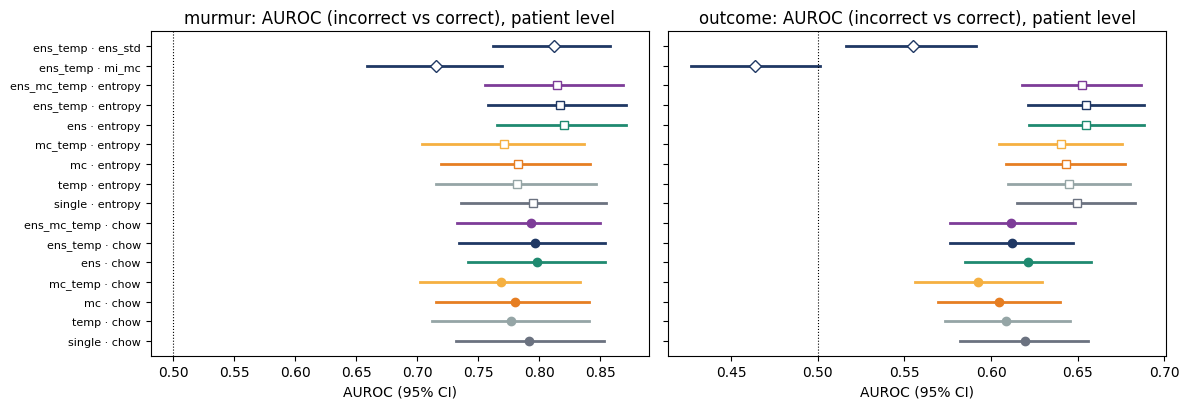

In [16]:
def aurc(err, risk, tb):
    return float(risk_coverage(err, risk, tb)[1].mean())

sel_point, sel_boot = {}, {}
for lvl in LEVELS:
    for task in TASKS:
        idx = EVAL[(lvl, task)]; tb = TIEB[lvl][idx]
        for m, sc in COMBOS:
            err = 1 - D[(lvl, task, m)]["correct"][idx]; risk = D[(lvl, task, m)][sc][idx]
            sel_point[(lvl, task, m, sc)] = (auc_fast(err, risk), aurc(err, risk, tb))
            sel_boot[(lvl, task, m, sc)] = np.array([(auc_fast(err[b], risk[b]), aurc(err[b], risk[b], tb[b])) for b in BI[(lvl, task)]])
sel_rows, seld_rows = [], []
for (lvl, task, m, sc), (a, r) in sel_point.items():
    bs = sel_boot[(lvl, task, m, sc)]
    sel_rows.append({"level": lvl, "task": task, "method": m, "score": sc, "n_errors": int(np.nansum(1 - D[(lvl, task, m)]["correct"][EVAL[(lvl, task)]])),
                     "AUROC": a, "AUROC_lo": np.nanpercentile(bs[:, 0], 2.5), "AUROC_hi": np.nanpercentile(bs[:, 0], 97.5),
                     "AURC": r, "AURC_lo": np.nanpercentile(bs[:, 1], 2.5), "AURC_hi": np.nanpercentile(bs[:, 1], 97.5)})
    refs = [("vs ens_temp · Chow", (lvl, task, PRIMARY, "chow"))] if (m, sc) != (PRIMARY, "chow") else []
    if sc == "chow":
        refs.append(("Chow − entropy", (lvl, task, m, "entropy")))
    for name, ref in refs:
        dd, dv = bs - sel_boot[ref], np.array([a, r]) - np.array(sel_point[ref])
        lo, hi = np.nanpercentile(dd, 2.5, axis=0), np.nanpercentile(dd, 97.5, axis=0)
        seld_rows.append({"level": lvl, "task": task, "comparison": f"{m} · {sc} {name}" if name != "Chow − entropy" else f"{m}: Chow − entropy",
                          "Δ AUROC (95% CI)": fmt_dci(dv[0], lo[0], hi[0]) + (" *" if lo[0] > 0 or hi[0] < 0 else ""),
                          "Δ AURC (95% CI)": fmt_dci(dv[1], lo[1], hi[1], 4) + (" *" if lo[1] > 0 or hi[1] < 0 else "")})
selective = pd.DataFrame(sel_rows)
selective["AUROC (95% CI)"] = [fmt_ci(r_.AUROC, r_.AUROC_lo, r_.AUROC_hi) for r_ in selective.itertuples()]
selective["AURC (95% CI)"] = [fmt_ci(r_.AURC, r_.AURC_lo, r_.AURC_hi, 4) for r_ in selective.itertuples()]
selective_diff = pd.DataFrame(seld_rows)
for lvl in LEVELS:
    print(f"\n===== {lvl} level =====")
    s = selective[selective.level == lvl]
    display(s.assign(m=s.method + " · " + s.score).pivot_table(index="m", columns="task", values=["AUROC (95% CI)", "AURC (95% CI)"], aggfunc="first"))
    display(selective_diff[selective_diff.level == lvl].pivot_table(index="comparison", columns="task",
                                                                    values=["Δ AUROC (95% CI)", "Δ AURC (95% CI)"], aggfunc="first"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
s = selective[(selective.level == "patient")]
labels = [f"{m} · {sc}" for m, sc in COMBOS]
for ax, task in zip(axes, TASKS):
    for i, (m, sc) in enumerate(COMBOS):
        r_ = s[(s.task == task) & (s.method == m) & (s.score == sc)].iloc[0]
        ax.plot([r_.AUROC_lo, r_.AUROC_hi], [i, i], color=METHOD_COLOR[m], lw=2)
        ax.plot(r_.AUROC, i, "o" if sc == "chow" else ("s" if sc == "entropy" else "D"), color=METHOD_COLOR[m], ms=6,
                mfc=METHOD_COLOR[m] if sc == "chow" else "white")
    ax.axvline(0.5, color="black", lw=0.8, ls=":")
    ax.set(title=f"{task}: AUROC (incorrect vs correct), patient level", xlabel="AUROC (95% CI)")
axes[0].set_yticks(range(len(labels))); axes[0].set_yticklabels(labels, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "rq4_selective_auroc.png", dpi=200); plt.show()

## 12. Analysis H — comparison with the literature (single points; neither paper published a curve)

*Components: ④ UQ.*

| paper | what it reports | our like-for-like number |
|---|---|---|
| **De Simone et al. 2025** (arXiv 2511.00966), CirCor, Present vs Absent (Unknown excluded from training) | rejecting ≈ 20 % of 2-s **segments** (score: MC entropy + coherence); patient-level results. Light model: accuracy 91.18 → 91.40 %, recall 79.80 → 82.83 %, precision 80.61 → 79.61 %. (Heavy model: recall 80.81 → 75.76 %.) No ECE. | change in accuracy, recall (sensitivity) and precision at **20 % rejection**, murmur, patient level |
| **Zhang et al. 2024** (ICASSP), CirCor, 3 classes, MC-Dropout 30 passes + temperature scaling | ECE 0.098 → 0.043 at patient level (−56 %), 0.063 → 0.049 at segment level (−22 %); 15 bins. No rejection results. | relative ECE change from temperature scaling: `mc → mc_temp` (like-for-like), `single → temp`, `ens → ens_temp`, murmur, patient (and recording) level |

Differences that remain (stated in the report): our unit of rejection is the patient, not the segment; our murmur task is binary; our ECE uses 10 bins.

In [17]:
lit_rows = []
for m in METHODS:
    for q in ["Accuracy", "Sensitivity", "Precision"]:
        r_ = rates_df[(rates_df.level == "patient") & (rates_df.task == "murmur") & (rates_df.method == m) & (rates_df.score == "chow")
                      & (rates_df.rate == 0.2)]
        after = r_[r_.quantity == q]; ch = r_[r_.quantity == f"{q} — change from before"]
        b0 = rates_df[(rates_df.level == "patient") & (rates_df.task == "murmur") & (rates_df.method == m) & (rates_df.score == "chow")
                      & (rates_df.rate == 0.0) & (rates_df.quantity == q)].iloc[0]
        lit_rows.append({"comparison": "De Simone (20 % rejection)", "method": m, "quantity": q, "before": b0.value,
                         "after": after.iloc[0].value, "change (95% CI)": ch.iloc[0]["value (95% CI)"]})
desimone = pd.DataFrame(lit_rows)
print("De Simone et al. (Light model): accuracy +0.22 pp, recall +3.03 pp, precision −1.00 pp at ~20 % segment rejection")
display(desimone.pivot_table(index="method", columns="quantity", values="change (95% CI)", aggfunc="first").reindex(METHODS))

zh_rows = []
for lvl in LEVELS:
    for a_, b_ in [("mc", "mc_temp"), ("single", "temp"), ("ens", "ens_temp"), ("ens", "ens_mc_temp")]:
        ka, kb = (lvl, "murmur", a_, "chow"), (lvl, "murmur", b_, "chow")
        ea, eb = rate_point[ka][0.0]["ECE"], rate_point[kb][0.0]["ECE"]
        rel = np.array([bt_b[0.0]["ECE"] / bt_a[0.0]["ECE"] - 1 for bt_a, bt_b in zip(rate_boot[ka], rate_boot[kb])])
        lo, hi = np.nanpercentile(rel, [2.5, 97.5])
        zh_rows.append({"level": lvl, "comparison": f"{a_} → {b_}", "ECE before": ea, "ECE after": eb,
                        "relative change (95% CI)": f"{eb / ea - 1:+.1%} [{lo:+.1%}, {hi:+.1%}]"})
zhang = pd.DataFrame(zh_rows)
print("Zhang et al.: patient-level ECE −56 % (0.098 → 0.043), segment-level −22 % (0.063 → 0.049)")
display(zhang.round(4))

De Simone et al. (Light model): accuracy +0.22 pp, recall +3.03 pp, precision −1.00 pp at ~20 % segment rejection


quantity,Accuracy,Precision,Sensitivity
method,,,
single,"+0.046 [+0.032, +0.058] *","+0.122 [+0.074, +0.179] *","+0.097 [+0.052, +0.139] *"
temp,"+0.041 [+0.028, +0.055] *","+0.114 [+0.069, +0.172] *","+0.080 [+0.038, +0.122] *"
mc,"+0.041 [+0.028, +0.054] *","+0.106 [+0.060, +0.160] *","+0.090 [+0.047, +0.135] *"
mc_temp,"+0.037 [+0.026, +0.050] *","+0.099 [+0.060, +0.152] *","+0.079 [+0.038, +0.123] *"
ens,"+0.047 [+0.034, +0.063] *","+0.152 [+0.102, +0.209] *","+0.064 [+0.030, +0.115] *"
ens_temp,"+0.049 [+0.036, +0.065] *","+0.165 [+0.114, +0.222] *","+0.060 [+0.021, +0.100] *"
ens_mc_temp,"+0.048 [+0.034, +0.064] *","+0.161 [+0.109, +0.216] *","+0.059 [+0.021, +0.100] *"


Zhang et al.: patient-level ECE −56 % (0.098 → 0.043), segment-level −22 % (0.063 → 0.049)


,level,comparison,ECE before,ECE after,relative change (95% CI)
0,patient,mc → mc_temp,0.0865,0.0765,"-11.6% [-22.0%, -6.1%]"
1,patient,single → temp,0.0811,0.0748,"-7.7% [-16.0%, -2.3%]"
2,patient,ens → ens_temp,0.0667,0.0645,"-3.3% [-10.8%, +6.4%]"
3,patient,ens → ens_mc_temp,0.0667,0.0650,"-2.5% [-10.0%, +7.2%]"
4,recording,mc → mc_temp,0.0210,0.0292,"+38.5% [-9.2%, +93.2%]"
5,recording,single → temp,0.0212,0.0261,"+23.3% [-13.3%, +68.7%]"
6,recording,ens → ens_temp,0.0213,0.0288,"+35.1% [-4.9%, +67.8%]"
7,recording,ens → ens_mc_temp,0.0213,0.0283,"+32.6% [-2.9%, +68.7%]"


## 13. The pre-set answer rule, applied

*Components: ④ UQ → RQ4's answer.*

Primary: `ens_temp`, Chow score, patient level, each task and rate. Recording level and the entropy score are shown as sensitivity checks.

| verdict | condition (95 % CIs) |
|---|---|
| **genuine calibration gain** | ΔECE after − before < 0 **and** ΔECE vs random < 0 |
| gain vs random only | ΔECE vs random < 0, but no clear drop from before |
| **no gain beyond random** | ΔECE vs random includes 0 |
| worse than random | ΔECE vs random > 0 |

"Hard cases" columns: share of rejected that were correct vs the starting accuracy; Present/Abnormal deferred vs the rate; grade-I murmurs deferred vs the rate (patient-level murmur only). A positive difference means rejection removes that group *more* than random rejection would.

In [18]:
def get(lvl, task, m, sc, r, q):
    s = rates_df[(rates_df.level == lvl) & (rates_df.task == task) & (rates_df.method == m) & (rates_df.score == sc)
                 & (rates_df.rate == r) & (rates_df.quantity == q)]
    return s.iloc[0] if len(s) else None

ans_rows = []
for lvl in LEVELS:
    for sc in ["chow", "entropy"]:
        for task in TASKS:
            for r in cfg.rates:
                ba, vr = get(lvl, task, PRIMARY, sc, r, "ECE — change from before"), get(lvl, task, PRIMARY, sc, r, "ECE — vs random rejection")
                if vr.ci_high < 0 and ba.ci_high < 0:
                    verdict = "genuine calibration gain"
                elif vr.ci_high < 0:
                    verdict = "gain vs random only"
                elif vr.ci_low > 0:
                    verdict = "worse than random"
                else:
                    verdict = "no gain beyond random"
                row = {"level": lvl, "score": sc, "task": task, "rate": r,
                       "ECE before → retained": f"{get(lvl, task, PRIMARY, sc, 0.0, 'ECE').value:.3f} → {get(lvl, task, PRIMARY, sc, r, 'ECE').value:.3f}",
                       "Δ after − before": ba["value (95% CI)"], "Δ vs random": vr["value (95% CI)"], "verdict": verdict,
                       "rejected correct − random": get(lvl, task, PRIMARY, sc, r, "share of rejected that were correct — vs random rejection")["value (95% CI)"],
                       "positives deferred − rate": get(lvl, task, PRIMARY, sc, r, "share of positives deferred — vs random rejection")["value (95% CI)"]}
                g = get(lvl, task, PRIMARY, sc, r, "share deferred: grade I — vs random rejection")
                row["grade I deferred − rate"] = g["value (95% CI)"] if g is not None else ""
                ans_rows.append(row)
answer = pd.DataFrame(ans_rows)
for lvl in LEVELS:
    for sc in ["chow", "entropy"]:
        print(f"\n===== {lvl} level · ens_temp · {SCORE_NAME[sc]}{'  (PRIMARY)' if (lvl, sc) == ('patient', 'chow') else ''} =====")
        display(answer[(answer.level == lvl) & (answer.score == sc)].drop(columns=["level", "score"]).reset_index(drop=True))


===== patient level · ens_temp · Chow (threshold-aware)  (PRIMARY) =====


,task,rate,ECE before → retained,Δ after − before,Δ vs random,verdict,rejected correct − random,positives deferred − rate,grade I deferred − rate
0,murmur,0.1,0.065 → 0.054,"-0.011 [-0.018, -0.001] *","-0.011 [-0.018, -0.002] *",genuine calibration gain,"-0.290 [-0.391, -0.210] *","+0.012 [-0.024, +0.057]","+0.083 [+0.027, +0.164] *"
1,murmur,0.2,0.065 → 0.048,"-0.017 [-0.029, -0.008] *","-0.018 [-0.030, -0.009] *",genuine calibration gain,"-0.196 [-0.260, -0.143] *","+0.007 [-0.047, +0.067]","+0.146 [+0.063, +0.230] *"
2,murmur,0.3,0.065 → 0.036,"-0.028 [-0.041, -0.016] *","-0.030 [-0.042, -0.018] *",genuine calibration gain,"-0.124 [-0.164, -0.092] *","-0.004 [-0.060, +0.060]","+0.152 [+0.066, +0.244] *"
3,murmur,0.5,0.065 → 0.013,"-0.052 [-0.066, -0.037] *","-0.056 [-0.069, -0.041] *",genuine calibration gain,"-0.057 [-0.077, -0.040] *","-0.126 [-0.192, -0.054] *","+0.048 [-0.042, +0.138]"
4,outcome,0.1,0.049 → 0.055,"+0.006 [-0.005, +0.017]","+0.005 [-0.006, +0.017]",no gain beyond random,"-0.086 [-0.175, +0.016]","-0.021 [-0.040, +0.000]",
5,outcome,0.2,0.049 → 0.057,"+0.008 [-0.007, +0.022]","+0.006 [-0.008, +0.021]",no gain beyond random,"-0.049 [-0.129, +0.012]","-0.038 [-0.065, -0.011] *",
6,outcome,0.3,0.049 → 0.052,"+0.003 [-0.014, +0.025]","-0.000 [-0.016, +0.023]",no gain beyond random,"-0.095 [-0.144, -0.042] *","-0.063 [-0.095, -0.034] *",
7,outcome,0.5,0.049 → 0.048,"-0.001 [-0.013, +0.043]","-0.008 [-0.020, +0.035]",no gain beyond random,"-0.074 [-0.104, -0.043] *","-0.099 [-0.129, -0.061] *",



===== patient level · ens_temp · entropy =====


,task,rate,ECE before → retained,Δ after − before,Δ vs random,verdict,rejected correct − random,positives deferred − rate,grade I deferred − rate
0,murmur,0.1,0.065 → 0.057,"-0.008 [-0.016, +0.000]","-0.008 [-0.017, -0.000] *",gain vs random only,"-0.359 [-0.479, -0.270] *","+0.045 [+0.010, +0.100] *","+0.131 [+0.074, +0.218] *"
1,murmur,0.2,0.065 → 0.049,"-0.016 [-0.028, -0.006] *","-0.017 [-0.029, -0.008] *",genuine calibration gain,"-0.196 [-0.265, -0.143] *","+0.085 [+0.027, +0.147] *","+0.233 [+0.146, +0.319] *"
2,murmur,0.3,0.065 → 0.038,"-0.027 [-0.041, -0.017] *","-0.029 [-0.042, -0.019] *",genuine calibration gain,"-0.140 [-0.179, -0.104] *","+0.041 [-0.026, +0.106]","+0.219 [+0.127, +0.306] *"
3,murmur,0.5,0.065 → 0.016,"-0.048 [-0.065, -0.036] *","-0.053 [-0.068, -0.039] *",genuine calibration gain,"-0.062 [-0.081, -0.045] *","-0.081 [-0.150, -0.005] *","+0.115 [+0.023, +0.207] *"
4,outcome,0.1,0.049 → 0.040,"-0.009 [-0.016, +0.010]","-0.010 [-0.017, +0.008]",no gain beyond random,"-0.203 [-0.289, -0.105] *","-0.023 [-0.041, -0.003] *",
5,outcome,0.2,0.049 → 0.034,"-0.015 [-0.022, +0.015]","-0.017 [-0.024, +0.012]",no gain beyond random,"-0.182 [-0.233, -0.109] *","-0.040 [-0.063, -0.012] *",
6,outcome,0.3,0.049 → 0.044,"-0.005 [-0.021, +0.021]","-0.008 [-0.025, +0.017]",no gain beyond random,"-0.112 [-0.169, -0.073] *","-0.032 [-0.071, -0.009] *",
7,outcome,0.5,0.049 → 0.048,"-0.001 [-0.019, +0.037]","-0.008 [-0.027, +0.029]",no gain beyond random,"-0.096 [-0.131, -0.068] *","-0.057 [-0.097, -0.026] *",



===== recording level · ens_temp · Chow (threshold-aware) =====


,task,rate,ECE before → retained,Δ after − before,Δ vs random,verdict,rejected correct − random,positives deferred − rate,grade I deferred − rate
0,murmur,0.1,0.029 → 0.032,"+0.003 [-0.004, +0.007]","+0.003 [-0.004, +0.007]",no gain beyond random,"-0.458 [-0.521, -0.398] *","-0.004 [-0.028, +0.026]",
1,murmur,0.2,0.029 → 0.028,"-0.001 [-0.009, +0.005]","-0.001 [-0.009, +0.005]",no gain beyond random,"-0.294 [-0.332, -0.251] *","+0.014 [-0.022, +0.048]",
2,murmur,0.3,0.029 → 0.021,"-0.008 [-0.017, -0.000] *","-0.008 [-0.018, -0.001] *",genuine calibration gain,"-0.200 [-0.228, -0.174] *","+0.043 [-0.007, +0.092]",
3,murmur,0.5,0.029 → 0.012,"-0.017 [-0.027, -0.009] *","-0.019 [-0.028, -0.011] *",genuine calibration gain,"-0.099 [-0.113, -0.085] *","-0.021 [-0.082, +0.039]",
4,outcome,0.1,0.050 → 0.054,"+0.004 [-0.002, +0.010]","+0.003 [-0.002, +0.010]",no gain beyond random,"-0.087 [-0.143, -0.039] *","-0.019 [-0.031, -0.009] *",
5,outcome,0.2,0.050 → 0.056,"+0.006 [-0.003, +0.017]","+0.006 [-0.004, +0.017]",no gain beyond random,"-0.074 [-0.113, -0.031] *","-0.033 [-0.049, -0.018] *",
6,outcome,0.3,0.050 → 0.059,"+0.009 [-0.000, +0.026]","+0.009 [-0.000, +0.025]",no gain beyond random,"-0.072 [-0.095, -0.033] *","-0.056 [-0.075, -0.033] *",
7,outcome,0.5,0.050 → 0.077,"+0.027 [+0.010, +0.047] *","+0.026 [+0.008, +0.045] *",worse than random,"-0.064 [-0.085, -0.042] *","-0.085 [-0.111, -0.058] *",



===== recording level · ens_temp · entropy =====


,task,rate,ECE before → retained,Δ after − before,Δ vs random,verdict,rejected correct − random,positives deferred − rate,grade I deferred − rate
0,murmur,0.1,0.029 → 0.023,"-0.006 [-0.013, -0.002] *","-0.006 [-0.013, -0.002] *",genuine calibration gain,"-0.255 [-0.324, -0.193] *","+0.152 [+0.115, +0.191] *",
1,murmur,0.2,0.029 → 0.019,"-0.010 [-0.019, -0.004] *","-0.010 [-0.019, -0.005] *",genuine calibration gain,"-0.268 [-0.309, -0.221] *","+0.160 [+0.113, +0.215] *",
2,murmur,0.3,0.029 → 0.016,"-0.013 [-0.024, -0.006] *","-0.013 [-0.025, -0.006] *",genuine calibration gain,"-0.191 [-0.224, -0.164] *","+0.148 [+0.095, +0.208] *",
3,murmur,0.5,0.029 → 0.015,"-0.014 [-0.026, -0.005] *","-0.016 [-0.027, -0.007] *",genuine calibration gain,"-0.097 [-0.113, -0.081] *","+0.084 [+0.025, +0.150] *",
4,outcome,0.1,0.050 → 0.050,"-0.000 [-0.006, +0.011]","-0.000 [-0.006, +0.011]",no gain beyond random,"-0.106 [-0.168, -0.048] *","-0.008 [-0.020, +0.004]",
5,outcome,0.2,0.050 → 0.043,"-0.007 [-0.017, +0.014]","-0.007 [-0.017, +0.013]",no gain beyond random,"-0.135 [-0.184, -0.093] *","-0.028 [-0.048, -0.010] *",
6,outcome,0.3,0.050 → 0.048,"-0.002 [-0.019, +0.023]","-0.003 [-0.020, +0.022]",no gain beyond random,"-0.130 [-0.169, -0.094] *","-0.038 [-0.063, -0.015] *",
7,outcome,0.5,0.050 → 0.057,"+0.007 [-0.017, +0.033]","+0.006 [-0.019, +0.030]",no gain beyond random,"-0.104 [-0.131, -0.080] *","-0.056 [-0.086, -0.031] *",


## 14. Save everything later notebooks need

*Components: ④ → RQ6's confidence gate; RQ1 and RQ5 read the scores.*

| file | contents | used by |
|---|---|---|
| `units_mc/joint_domain_f*_s{123,7}.npz` | the regenerated MC passes (both heads) | RQ6 |
| `rq4_patient_scores.csv`, `rq4_recording_scores.csv` | per task × method × unit: probability, threshold, decision, correct, Chow risk, entropy (+ MC MI and ensemble spread for `ens_temp`), systolic grade | RQ6, RQ1, RQ5 |
| `rq4_temperatures.csv`, `rq4_thresholds.csv` | deterministic and MC temperatures; thresholds for all 7 methods | RQ6 |
| `rq4_curves.csv`, `rq4_ece_curves.csv` | accuracy–rejection and ECE–rejection curves | report |
| `rq4_rates.csv` | every metric and difference at 0/10/20/30/50 % with CIs | report, RQ6 |
| `rq4_selective.csv`, `rq4_selective_differences.csv` | AUROC, AURC and their paired differences | report |
| `rq4_unknown_check.csv`, `rq4_literature_desimone.csv`, `rq4_literature_zhang.csv`, `rq4_answer.csv` | analyses E, H and the answer rule | report |

In [19]:
for lvl, fname in [("patient", "rq4_patient_scores.csv"), ("recording", "rq4_recording_scores.csv")]:
    base = (PAT[["patient_id", "group", "fold", "murmur", "outcome", "systolic_grade"]] if lvl == "patient"
            else man[["wid", "patient_id", "group", "location", "fold", "murmur", "outcome"]])
    frames = []
    for task in TASKS:
        for m in METHODS:
            d = D[(lvl, task, m)]
            df = base.copy(); df.insert(0, "method", m); df.insert(0, "task", task)
            for k in ["y", "p", "t", "yhat", "correct", "chow", "entropy"] + (["mi_mc", "ens_std"] if m == PRIMARY else []):
                df[{"t": "threshold", "yhat": "pred", "chow": "risk_chow"}.get(k, k)] = d[k]
            frames.append(df)
    pd.concat(frames).to_csv(OUT / fname, index=False)
temps.to_csv(OUT / "rq4_temperatures.csv", index=False)
thresholds.to_csv(OUT / "rq4_thresholds.csv", index=False)
curves.to_csv(OUT / "rq4_curves.csv", index=False)
ece_curves.to_csv(OUT / "rq4_ece_curves.csv", index=False)
rates_df.to_csv(OUT / "rq4_rates.csv", index=False)
selective.to_csv(OUT / "rq4_selective.csv", index=False)
selective_diff.to_csv(OUT / "rq4_selective_differences.csv", index=False)
unknown.to_csv(OUT / "rq4_unknown_check.csv", index=False)
desimone.to_csv(OUT / "rq4_literature_desimone.csv", index=False)
zhang.to_csv(OUT / "rq4_literature_zhang.csv", index=False)
answer.to_csv(OUT / "rq4_answer.csv", index=False)
print("saved to", OUT)
for p_ in sorted(OUT.rglob("*")):
    if p_.is_file():
        print(f"  {p_.relative_to(OUT)}  ({p_.stat().st_size / 1e6:.2f} MB)")

saved to /kaggle/working/rq4_outputs
  figures/rq4_accuracy_rejection_methods.png  (0.51 MB)
  figures/rq4_accuracy_rejection_scores.png  (0.49 MB)
  figures/rq4_ece_rejection.png  (0.52 MB)
  figures/rq4_reliability_20.png  (0.18 MB)
  figures/rq4_selective_auroc.png  (0.12 MB)
  rq4_answer.csv  (0.01 MB)
  rq4_curves.csv  (8.33 MB)
  rq4_ece_curves.csv  (0.54 MB)
  rq4_literature_desimone.csv  (0.00 MB)
  rq4_literature_zhang.csv  (0.00 MB)
  rq4_patient_scores.csv  (1.64 MB)
  rq4_rates.csv  (0.71 MB)
  rq4_recording_scores.csv  (5.95 MB)
  rq4_selective.csv  (0.01 MB)
  rq4_selective_differences.csv  (0.01 MB)
  rq4_temperatures.csv  (0.00 MB)
  rq4_thresholds.csv  (0.00 MB)
  rq4_unknown_check.csv  (0.00 MB)
  units_mc/joint_domain_f0_s123.npz  (3.89 MB)
  units_mc/joint_domain_f0_s7.npz  (3.89 MB)
  units_mc/joint_domain_f1_s123.npz  (3.88 MB)
  units_mc/joint_domain_f1_s7.npz  (3.88 MB)
  units_mc/joint_domain_f2_s123.npz  (3.89 MB)
  units_mc/joint_domain_f2_s7.npz  (3.87 MB)
